# ID6004W Industrial Vision - Assignment 3
### Lectures 07-13: SIFT, Projective Geometry, Cameras, and Homographies

| | |
|---|---|
| **Released** | Oct 24th 2026 |
| **Due** | Nov 11th 2026 (5.00 PM IST) |
| **Total** | 100 marks (Theory 60 + Programming 40; will be scaled down appropriately later) |

## Instructions

**Working in Colab.** Open this notebook in Google Colab and immediately use *File → Save a copy in Drive*; work only in your copy. Type your answers in the cells marked **Your answer**, directly below each question (double-click a cell to edit it). Mathematics can be typed in LaTeX between `$...$` or `$$...$$`. Photographs of hand-written working are **not** accepted in place of typed answers.

- **The writing must be your own**, for both the theory answers and the code.
- Wherever a numerical answer is asked for, show the intermediate steps.
- Cells marked **Optional check** are not graded. Use them to verify a hand calculation numerically, but the answer you submit must be derived by hand with the steps shown.
- Part B is done in this notebook, and the notebook is also your report: the cells make the figures, and your written answers go in the **Your answer** cells of Part B. Run every cell from top to bottom (*Runtime → Restart and run all*) before you submit, so that all outputs and figures are visible in the file.
- **Submission.** Make a **single `.zip`** named `<ROLLNO>_assignment3.zip` that contains (1) this notebook with all outputs, downloaded with *File → Download → Download .ipynb* and named `<ROLLNO>_assignment3.ipynb`, and (2) the photographs you took for Part B. Upload it here: [SUBMISSION LINK](https://forms.gle/kem7ogoLSk89omW39). For queries contact Rishabh Shukla (da26e011@smail.iitm.ac.in). The form link will be disabled after the deadline. Follow the naming convention strictly.
- **Late policy:** 10 marks will be deducted for each day the assignment is submitted late after the due date.

## Student details

- **Name:** Amardeep Kumar
- **Roll number:** DA25M502

In [1]:

# Assignment 3: Dataset Setup

import zipfile
from pathlib import Path

BASE = Path("/content")
DATA = BASE / "assignment3_data"

if not DATA.is_dir():

    # Find uploaded ZIP file in Colab
    zip_files = list(BASE.glob("assignment3_data*.zip"))

    if not zip_files:
        raise FileNotFoundError(
            "Please upload assignment3_data.zip using Colab's Files section."
        )

    zip_path = next(
        (p for p in zip_files if zipfile.is_zipfile(p)), None
    )

    print("Found:", zip_path)
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(BASE)

# Verify extraction
if not DATA.is_dir():
    raise FileNotFoundError("Dataset extraction failed.")

print("\nDataset setup successful!")
print(DATA, "->", sorted(p.name for p in DATA.iterdir()))



Dataset setup successful!
/content/assignment3_data -> ['aloeL.jpg', 'aloeR.jpg', 'boat1.jpg', 'boat2.jpg', 'boat3.jpg', 'boat4.jpg', 'boat5.jpg', 'newspaper1.jpg', 'newspaper2.jpg', 'sample_output']


In [2]:
import os
import sys
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV", cv2.__version__)       # SIFT needs OpenCV >= 4.4; Colab's default is fine

OpenCV 5.0.0


---
# Part A - Theory  [60 marks]

---
## Question 1. SIFT: blur levels, refinement and the descriptor  [14 marks]

**(a) Blur levels in one octave.** **[4]**

Lowe's SIFT uses $s=3$ scales per octave, and each octave starts at $\sigma_0=1.6$.

1. Find $k$ and the six blur levels $\sigma_0,\dots,\sigma_5$ of the first octave (three decimals). Which three DoG levels are searched for extrema, and why not the other two?
2. The level $\sigma_3=3.2$ is made by blurring the level $\sigma_2$ once more, not the original image. What standard deviation must this extra blur have?
3. A student uses an extra blur of $\sigma_3-\sigma_2$ instead. What $\sigma$ does their level really have? In one sentence, what rule did they get wrong?

### Answer 1(a).

### 1. Scale Multiplier, Blur Levels, and DoG Extrema Detection

The scale factor between consecutive levels in an octave is given by:

$$k = 2^{1/s} = 2^{1/3} \approx 1.25992 \dots \approx 1.260$$

Using $\sigma_i = \sigma_0 \cdot k^i$ with $\sigma_0 = 1.6$:

* $\sigma_0 = 1.6 \times 2^{0/3} = \mathbf{1.600}$
* $\sigma_1 = 1.6 \times 2^{1/3} \approx \mathbf{2.016}$
* $\sigma_2 = 1.6 \times 2^{2/3} \approx \mathbf{2.540}$
* $\sigma_3 = 1.6 \times 2^{3/3} = 1.6 \times 2 = \mathbf{3.200}$
* $\sigma_4 = 1.6 \times 2^{4/3} \approx \mathbf{4.032}$
* $\sigma_5 = 1.6 \times 2^{5/3} \approx \mathbf{5.080}$

---

#### DoG Levels Searched for Extrema

Subtracting adjacent Gaussian levels yields $s + 2 = 5$ Difference-of-Gaussian (DoG) images:

* $D_0 = L(\sigma_1) - L(\sigma_0)$
* $D_1 = L(\sigma_2) - L(\sigma_1)$
* $D_2 = L(\sigma_3) - L(\sigma_2)$
* $D_3 = L(\sigma_4) - L(\sigma_3)$
* $D_4 = L(\sigma_5) - L(\sigma_4)$

The three middle DoG levels searched for extrema are **$D_1, D_2,$ and $D_3$** (corresponding to scales $\sigma_1, \sigma_2,$ and $\sigma_3$).

**Why not the other two?**
Keypoint detection compares each sample point to its 26 neighbors in a $3 \times 3 \times 3$ volume (8 neighbors in the current scale, and 9 in each adjacent scale above and below). The top and bottom levels, **$D_0$ and $D_4$**, cannot be evaluated for scale-space extrema because they lack an adjacent neighbor above or below them.

---

### 2. Required Incremental Blur Standard Deviation

Convolving an image with two successive Gaussians with standard deviations $\sigma_a$ and $\sigma_{\text{add}}$ produces an effective Gaussian blur of $\sigma_b$, following the quadrature sum:

$$\sigma_b^2 = \sigma_a^2 + \sigma_{\text{add}}^2 \implies \sigma_{\text{add}} = \sqrt{\sigma_b^2 - \sigma_a^2}$$

For blurring from $\sigma_2$ to $\sigma_3$:

$$\sigma_{\text{add}} = \sqrt{\sigma_3^2 - \sigma_2^2} = \sqrt{(3.2)^2 - (1.6 \times 2^{2/3})^2} = \sqrt{10.24 - 6.4508} = \sqrt{3.7892} \approx \mathbf{1.947}$$

---

### 3. Student Error Analysis

If the student uses an incremental blur of $\sigma_{\text{extra}} = \sigma_3 - \sigma_2$:

$$\sigma_{\text{extra}} = 3.2 - 2.5398 \approx 0.6602$$

The actual resulting blur $\sigma_{\text{actual}}$ is:

$$\sigma_{\text{actual}} = \sqrt{\sigma_2^2 + (\sigma_3 - \sigma_2)^2} = \sqrt{2.5398^2 + 0.6602^2} = \sqrt{6.4508 + 0.4358} = \sqrt{6.8866} \approx \mathbf{2.624}$$

**Rule violation:**
Independent Gaussian convolutions add their variances in quadrature ($\sigma^2 = \sigma_1^2 + \sigma_2^2$), not linearly by standard deviation.

**(b) Refining a keypoint, and the two rejection tests.** **[5]**

A DoG extremum found on the sample grid has value $D=0.045$, and gradient and Hessian

$$
\nabla D=\begin{bmatrix}0.012\\-0.006\\0.020\end{bmatrix},\qquad
\mathbf H_D=\begin{bmatrix}-0.10&0.02&0.00\\0.02&-0.08&0.01\\0.00&0.01&-0.05\end{bmatrix},
$$

with the coordinates in the order $(x,y,\sigma)$.

1. Compute the sub-pixel offset $\hat{\mathbf{x}}=-\mathbf H_D^{-1}\nabla D$ (three decimals). Do we need to move to a neighbouring sample and fit again?
2. Compute the DoG value at the refined position and apply the contrast test with threshold $0.03$.
3. Apply the edge test with $r_{\max}=10$ to this keypoint (use the $2\times2$ spatial part of $\mathbf H_D$). Then apply it to a second keypoint whose $2\times2$ spatial Hessian is $\begin{bmatrix}-0.30&0.05\\0.05&-0.02\end{bmatrix}$. For the keypoint that is rejected, find the ratio $r$ of its two principal curvatures.

### Answer 1(b).

### 1. Sub-pixel Offset Calculation

The sub-pixel offset $\hat{\mathbf{x}} = \begin{bmatrix} \hat{x} & \hat{y} & \hat{\sigma} \end{bmatrix}^T$ is given by:

$$\hat{\mathbf{x}} = -\mathbf{H}_D^{-1}\nabla D$$

#### Inverting the Hessian Matrix $\mathbf{H}_D$

$$\det(\mathbf{H}_D) = -0.10[(-0.08)(-0.05) - (0.01)^2] - 0.02[(0.02)(-0.05) - 0] = -0.10(0.0039) + 0.00002 = -0.00037$$

Computing $-\mathbf{H}_D^{-1} = -\frac{1}{\det(\mathbf{H}_D)} \operatorname{adj}(\mathbf{H}_D)$:

$$-\mathbf{H}_D^{-1} = \frac{1}{0.00037}\begin{bmatrix} 0.0039 & 0.0010 & 0.0002 \\ 0.0010 & 0.0050 & 0.0010 \\ 0.0002 & 0.0010 & 0.0076 \end{bmatrix} = \frac{1}{37}\begin{bmatrix} 390 & 100 & 20 \\ 100 & 500 & 100 \\ 20 & 100 & 760 \end{bmatrix}$$

Multiplying by $\nabla D = \begin{bmatrix} 0.012 \\ -0.006 \\ 0.020 \end{bmatrix}$:

$$\hat{\mathbf{x}} = \frac{1}{37}\begin{bmatrix} 390(0.012) + 100(-0.006) + 20(0.020) \\ 100(0.012) + 500(-0.006) + 100(0.020) \\ 20(0.012) + 100(-0.006) + 760(0.020) \end{bmatrix} = \frac{1}{37}\begin{bmatrix} 4.48 \\ 0.20 \\ 14.84 \end{bmatrix} \approx \begin{bmatrix} \mathbf{0.121} \\ \mathbf{0.005} \\ \mathbf{0.401} \end{bmatrix}$$

#### Relocation Decision

**No, we do not need to move to a neighbouring sample.**

A keypoint must only be moved to an adjacent sample point if any component of $\hat{\mathbf{x}}$ has an absolute value greater than $0.5$. Since $\vert{}\hat{x}\vert{} = 0.121 < 0.5$, $\vert{}\hat{y}\vert{} = 0.005 < 0.5$, and $\vert{}\hat{\sigma}\vert{} = 0.401 < 0.5$, the interpolated extremum lies comfortably within the current grid cell.

---

### 2. Refined DoG Value and Contrast Test

The second-order Taylor expansion value at the refined position is:

$$D(\hat{\mathbf{x}}) = D + \frac{1}{2}\nabla D^T\hat{\mathbf{x}}$$

$$\nabla D^T\hat{\mathbf{x}} = (0.012)(0.12108) + (-0.006)(0.00541) + (0.020)(0.40108) \approx 0.001453 - 0.000032 + 0.008022 = 0.009443$$

$$D(\hat{\mathbf{x}}) = 0.045 + \frac{1}{2}(0.009443) = 0.045 + 0.004722 = \mathbf{0.0497} \quad (\approx \mathbf{0.050})$$

#### Contrast Test ($\text{Threshold} = 0.03$)

$$\vert{}D(\hat{\mathbf{x}})\vert{} = 0.0497 \ge 0.03$$

Since $\vert{}D(\hat{\mathbf{x}})\vert{} \ge 0.03$, the keypoint **passes the contrast test** and is retained.

---

### 3. Edge Response Elimination Test ($r_{\max} = 10$)

A keypoint is rejected if its principal curvatures along the edge profile are unbalanced, evaluated via:

$$\frac{\operatorname{Tr}(\mathbf{H})^2}{\det(\mathbf{H})} < \frac{(r_{\max} + 1)^2}{r_{\max}} = \frac{11^2}{10} = \mathbf{12.1}$$

#### Keypoint 1: $\mathbf{H}_1 = \begin{bmatrix}-0.10 & 0.02 \\ 0.02 & -0.08\end{bmatrix}$

* $\operatorname{Tr}(\mathbf{H}_1) = -0.10 + (-0.08) = -0.18$
* $\det(\mathbf{H}_1) = (-0.10)(-0.08) - (0.02)^2 = 0.0080 - 0.0004 = 0.0076 > 0$
* Curvature ratio metric:

$$\frac{\operatorname{Tr}(\mathbf{H}_1)^2}{\det(\mathbf{H}_1)} = \frac{(-0.18)^2}{0.0076} = \frac{0.0324}{0.0076} \approx \mathbf{4.263}$$



Since $4.263 < 12.1$, Keypoint 1 **passes the edge test** (accepted).

---

#### Keypoint 2: $\mathbf{H}_2 = \begin{bmatrix}-0.30 & 0.05 \\ 0.05 & -0.02\end{bmatrix}$

* $\operatorname{Tr}(\mathbf{H}_2) = -0.30 + (-0.02) = -0.32$
* $\det(\mathbf{H}_2) = (-0.30)(-0.02) - (0.05)^2 = 0.0060 - 0.0025 = 0.0035 > 0$
* Curvature ratio metric:

$$\frac{\operatorname{Tr}(\mathbf{H}_2)^2}{\det(\mathbf{H}_2)} = \frac{(-0.32)^2}{0.0035} = \frac{0.1024}{0.0035} \approx \mathbf{29.257}$$



Since $29.257 > 12.1$, Keypoint 2 **fails the edge test and is rejected**.

---

#### Ratio of Principal Curvatures ($r$) for Keypoint 2

The principal curvatures correspond to the eigenvalues of $\mathbf{H}_2$:

$$\lambda^2 - \operatorname{Tr}(\mathbf{H}_2)\lambda + \det(\mathbf{H}_2) = \lambda^2 + 0.32\lambda + 0.0035 = 0$$

$$\lambda = \frac{-0.32 \pm \sqrt{0.32^2 - 4(0.0035)}}{2} = \frac{-0.32 \pm \sqrt{0.0884}}{2} \approx \frac{-0.32 \pm 0.29732}{2}$$

* Larger magnitude curvature: $\vert{}\alpha\vert{} = \vert{}-0.30866\vert{} = 0.30866$
* Smaller magnitude curvature: $\vert{}\beta\vert{} = \vert{}-0.01134\vert{} = 0.01134$

$$r = \frac{\vert{}\alpha\vert{}}{\vert{}\beta\vert{}} = \frac{0.30866}{0.01134} \approx \mathbf{27.220}$$

In [36]:
# Optional check for 1(b).
D0 = 0.045
gD = np.array([0.012, -0.006, 0.020])
HD = np.array([[-0.10, 0.02, 0.00],
               [0.02, -0.08, 0.01],
               [0.00, 0.01, -0.05]])
H2 = np.array([[-0.30, 0.05],
               [0.05, -0.02]])

# TODO (optional): the offset, the refined DoG value, and tr^2/det for both spatial Hessians.

**(c) Invariance and matching.** **[5]**

1. A second photograph of the same scene has $I'=1.5\,I+20$. Which step of the descriptor computation removes the $+20$? Which step removes the factor $1.5$?
2. Now the second photograph is the first one rotated by $30^{\circ}$. The reference orientation $\theta$ of the keypoint is used in two places when the descriptor is built. Name both. What goes wrong if we only correct the gradient angles, and keep the sampling grid lined up with the image axes?
3. Two keypoints in image 1 are matched against image 2. Keypoint 1 has nearest and second-nearest descriptor distances $d_1=180$, $d_2=210$. Keypoint 2 has $d_1=250$, $d_2=480$. Apply Lowe's ratio test at $0.8$ to each. Then explain why a fixed rule "accept if $d_1<200$" gives the wrong decision for both.

### Answer 1(c).
### 1. Invariance to Affine Illumination Changes ($I' = 1.5\,I + 20$)

* **Removal of the $+20$ (additive shift / brightness change):**
This offset is eliminated when computing the **pixel gradients** ($\nabla I$). Because image gradients are calculated via differences between adjacent pixels:

$$\nabla I' = \nabla (1.5\,I + 20) = 1.5\,\nabla I$$



The constant derivative is zero ($\nabla(20) = 0$), so uniform additive intensity shifts vanish before forming orientation histograms.
* **Removal of the factor $1.5$ (multiplicative gain / contrast change):**
Multiplying pixel values by $1.5$ scales all gradient magnitudes by $1.5$, which directly scales the resulting 128-dimensional descriptor vector $\mathbf{v}$ by $1.5$. This factor is removed by **normalizing the descriptor to unit Euclidean length**:

$$\hat{\mathbf{v}} = \frac{\mathbf{v}}{\Vert{}\mathbf{v}\Vert{}_2} = \frac{1.5\,\mathbf{v}_{\text{orig}}}{\Vert{}1.5\,\mathbf{v}_{\text{orig}}\Vert{}_2} = \frac{\mathbf{v}_{\text{orig}}}{\Vert{}\mathbf{v}_{\text{orig}}\Vert{}_2}$$



---

### 2. Rotational Alignment of the SIFT Descriptor

The canonical keypoint orientation $\theta$ is used in two distinct places when building the descriptor:

1. **Rotating the spatial descriptor grid:** The $16 \times 16$ spatial neighborhood is rotated by $-\theta$ so that the $4 \times 4$ spatial sub-region bins align along the keypoint's intrinsic dominant orientation rather than the image coordinate axes.
2. **Rotating the gradient vectors:** Each sample point's gradient orientation $\phi(x,y)$ is shifted relative to the keypoint orientation: $\phi_{\text{relative}} = \phi(x,y) - \theta$.

#### What goes wrong if only gradient angles are rotated?

If the sampling grid remains aligned with the canonical image axes while only the gradient angles are offset by $-\theta$:

* While the individual gradient vectors now point in relative directions, **they are pooled into the wrong spatial sub-bins**.
* As the image rotates by $30^{\circ}$, image content that belonged to the top-left $4 \times 4$ spatial histogram shifts into neighboring bins.
* The resulting 128-dimensional vector will have its entries permuted and mixed across its 16 spatial histogram blocks, completely destroying rotation invariance.

---

### 3. Lowe's Ratio Test vs. Fixed Global Distance Threshold

Lowe's ratio criterion accepts a match if:

$$\frac{d_1}{d_2} < \tau = 0.8$$

#### Evaluation:

* **Keypoint 1:**

$$\frac{d_1}{d_2} = \frac{180}{210} \approx 0.857 \ge 0.8 \implies \mathbf{Reject}$$


* **Keypoint 2:**

$$\frac{d_1}{d_2} = \frac{250}{480} \approx 0.521 < 0.8 \implies \mathbf{Accept}$$



---

#### Why the Fixed Threshold "$d_1 < 200$" Fails for Both

A global threshold $d_1 < \text{threshold}$ evaluates matches in absolute distance without considering descriptor density or feature uniqueness:

* **Keypoint 1 ($d_1 = 180, d_2 = 210$):**
* *Fixed rule outcome:* Accepts ($180 < 200$).
* *Why it is wrong:* The second-nearest neighbor is almost as close as the nearest ($210$ vs $180$). This indicates an **ambiguous, repetitive, or cluttered texture** (e.g., foliage or background noise) where random chance can easily make an incorrect match slightly closer than the true one. It should be rejected.


* **Keypoint 2 ($d_1 = 250, d_2 = 480$):**
* *Fixed rule outcome:* Rejects ($250 \not< 200$).
* *Why it is wrong:* Keypoint 2 is in a sparser, high-dimensional region of descriptor space with some overall distortion (e.g., due to viewpoint or non-linear illumination changes), giving it a larger baseline distance. However, its nearest neighbor is **nearly twice as close as any alternative** ($250 \ll 480$), making it a distinctive and reliable true match.

---
## Question 2. SIFT: keypoints, orientation and octaves  [6 marks]

**(a) Is this a keypoint?** **[2]**

SIFT looks for keypoints in the DoG images. Below are the DoG values around one sample: its own level (middle), the level just below (left) and the level just above (right). The sample itself is the centre of the middle grid.

$$
\underbrace{\begin{bmatrix}0.01&0.02&0.00\\0.03&-0.02&0.01\\0.02&0.00&0.01\end{bmatrix}}_{\text{level below}}\qquad
\underbrace{\begin{bmatrix}0.02&0.01&0.03\\0.00&\mathbf{-0.06}&0.02\\0.01&0.02&0.00\end{bmatrix}}_{\text{same level}}\qquad
\underbrace{\begin{bmatrix}0.03&0.02&0.01\\0.02&-0.04&0.03\\0.01&0.03&0.02\end{bmatrix}}_{\text{level above}}
$$

1. How many values is the centre compared with, and where do they come from?
2. Is the centre kept as a keypoint? If it is, is it a maximum or a minimum, and does it mark a bright blob or a dark blob?
3. Suppose the value directly above the centre were $-0.07$ instead of $-0.04$. Would the centre still be kept? Why is it not enough to compare it only with its 8 neighbours in the same level?

### Answer 2(a).

### 1. Comparison Count

The centre sample is compared with **26 values** in total within a $3 \times 3 \times 3$ scale-space volume:

* **8 neighbours** from the **same scale level** (the 8 surrounding pixels in the current DoG image).
* **9 neighbours** from the **level below** (a full $3 \times 3$ patch at the lower adjacent scale).
* **9 neighbours** from the **level above** (a full $3 \times 3$ patch at the upper adjacent scale).

---

### 2. Keypoint Evaluation

The candidate centre value is **$-0.06$**.

Looking across all 26 neighbours:

* **Level below:** The lowest value is $-0.02$. Since $-0.06 < -0.02$, it is smaller than all 9 values in this level.
* **Same level:** The surrounding 8 neighbours are $\{0.02, 0.01, 0.03, 0.00, 0.02, 0.01, 0.02, 0.00\}$. The minimum among them is $0.00$. Since $-0.06 < 0.00$, it is strictly smaller than all 8 spatial neighbours.
* **Level above:** The lowest value is $-0.04$. Since $-0.06 < -0.04$, it is smaller than all 9 values in this level.

**Conclusion:**

* **Is it kept?** **Yes**, it is strictly smaller than all 26 neighbours on the discrete grid.
* **Extremum type:** It is a **local minimum** of the Difference-of-Gaussians function.
* **Blob type:** It marks a **bright blob**.
> **Note:** The Difference-of-Gaussians $D(x, y, \sigma) = L(x, y, k\sigma) - L(x, y, \sigma) \approx (k-1)\sigma^2 \nabla^2 L$ approximates the positive Laplacian of Gaussian. A negative extremum corresponds to a negative Laplacian ($\nabla^2 L < 0$ or negative curvature peak in intensity), which identifies a **bright blob**. (Conversely, a local maximum in DoG signifies a dark blob).



---

### 3. Change to $-0.07$ and Multi-Scale Search

* **Would it still be kept?**
**No.** If the value directly above were $-0.07$, the centre value $-0.06$ would no longer be the strict minimum in the $3 \times 3 \times 3$ neighborhood (since $-0.06 > -0.07$). Therefore, it would be discarded.
* **Why is comparing with the 8 spatial neighbours not enough?**
Comparing only across the 8 neighbours in the same plane detects spatial 2D extrema, but **fails to select the characteristic scale**. Scale-space extrema detection searches for features that are simultaneously localized in image coordinates $(x, y)$ and resonant at an intrinsic size across scale $\sigma$. Without checking adjacent scale levels, the detector cannot achieve **scale invariance**, as it would trigger on boundaries and arbitrary features regardless of whether their natural size matches that specific blur level.

**(b) The dominant orientation.** **[2]**

To give a keypoint an orientation, SIFT makes a histogram of the gradient angles around it, with 36 bins of $10^{\circ}$ (one bin for $0^{\circ}$-$10^{\circ}$, the next for $10^{\circ}$-$20^{\circ}$, and so on). Each pixel adds its **gradient magnitude** $m$ to the bin of its angle $\varphi$. The pixels around one keypoint have these gradients:

| pixel | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| magnitude $m$ | 5 | 3 | 2 | 4 | 4.5 | 1 | 1 | 1 | 1 |
| angle $\varphi$ | $42^{\circ}$ | $45^{\circ}$ | $47^{\circ}$ | $123^{\circ}$ | $127^{\circ}$ | $300^{\circ}$ | $302^{\circ}$ | $305^{\circ}$ | $308^{\circ}$ |

1. Fill in the histogram (only the bins that are not empty). Which bin gives the dominant orientation?
2. Every other peak that reaches at least $80\%$ of the highest one gives an extra keypoint. How many keypoints are made at this location, and how do they differ from each other?
3. A student adds $1$ for every pixel instead of its magnitude. Which bin wins now? Why is adding the magnitude better?

### Answer 2(b).

### 1. Orientation Histogram and Dominant Orientation

Each bin spans a $10^\circ$ interval:

* **Bin $40^\circ \text{–} 50^\circ$** (Pixels 1, 2, 3):

$$\text{Value} = 5 + 3 + 2 = \mathbf{10.0}$$


* **Bin $120^\circ \text{–} 130^\circ$** (Pixels 4, 5):

$$\text{Value} = 4 + 4.5 = \mathbf{8.5}$$


* **Bin $300^\circ \text{–} 310^\circ$** (Pixels 6, 7, 8, 9):

$$\text{Value} = 1 + 1 + 1 + 1 = \mathbf{4.0}$$



All other 33 bins have a value of **$0$**.

**Dominant orientation bin:**
The highest peak is **$10.0$**, so the dominant orientation is given by the bin **$40^\circ \text{–} 50^\circ$**.

---

### 2. Number of Keypoints and Differences

* **Peak 1 (Maximum):** $10.0$ (in bin $40^\circ \text{–} 50^\circ$)
* **Threshold for extra keypoints:** $80\%$ of highest peak $= 0.80 \times 10.0 = \mathbf{8.0}$
* **Peak 2:** $8.5$ (in bin $120^\circ \text{–} 130^\circ$)
* Since $8.5 \ge 8.0$, this peak qualifies as an additional keypoint.


* **Peak 3:** $4.0$ (in bin $300^\circ \text{–} 310^\circ$)
* Since $4.0 < 8.0$, it is discarded.



**Result:**

* **How many keypoints:** **$2$ keypoints** are created at this location.
* **How they differ:** Both keypoints share the exact same spatial location $(x, y)$ and scale $\sigma$, but they have **different reference orientations $\theta$** (one aligned near $45^\circ$ and the other near $125^\circ$), which leads to two distinct 128-dimensional feature descriptors.

---

### 3. Unweighted Voting (Count of 1 per Pixel)

If every pixel simply votes with a weight of $1$:

* **Bin $40^\circ \text{–} 50^\circ$:** $3$ votes
* **Bin $120^\circ \text{–} 130^\circ$:** $2$ votes
* **Bin $300^\circ \text{–} 310^\circ$:** $4$ votes
* **Winning bin:** The bin **$300^\circ \text{–} 310^\circ$** wins with $4$ votes.

#### Why weighting by magnitude is better:

Gradients with very small magnitudes typically originate from image noise or flat, untextured regions where the orientation angle $\varphi = \arctan(I_y / I_x)$ is unstable and noisy. Weighting votes by magnitude ensures that strong, physically meaningful image edges dictate the canonical orientation, while unreliable noise fluctuations are suppressed.

**(c) The descriptor, and octaves.** **[2]**

1. The SIFT descriptor uses a $16\times16$ window split into $4\times4$ blocks, and each block gives an 8-bin histogram. How many numbers are in the descriptor, and how many pixels are in each block? If the window were split into $2\times2$ blocks instead (still 8 bins each), how long would the descriptor be?
2. An image is $640\times480$. Ignore Lowe's doubling of the input image, so octave 1 is the image itself, and each new octave keeps every second pixel of every second row. Find the image size in octaves 2 and 3. A keypoint is found at $(100,60)$ in octave 3. Where is it in the original image? Its $16\times16$ descriptor window is measured in octave-3 pixels. How big is this window in the original image?

### Answer 2(c).

### 1. Descriptor Dimensions and Block Sizes

* **Total numbers in standard SIFT:**
A grid of $4 \times 4 = 16$ blocks with an 8-bin histogram per block yields:

$$16 \times 8 = \mathbf{128}\text{ values}$$


* **Pixels per block:**
A $16 \times 16$ window evenly split into $4 \times 4$ blocks gives sub-blocks of size:

$$\frac{16}{4} \times \frac{16}{4} = 4 \times 4 = \mathbf{16}\text{ pixels per block}$$


* **Length if split into $2 \times 2$ blocks:**
With $2 \times 2 = 4$ blocks and 8 bins per block:

$$4 \times 8 = \mathbf{32}\text{ values}$$



---

### 2. Octave Downsampling and Coordinate Mapping

Subsampling by keeping every second pixel of every second row halves the dimensions at each progressive octave:

* **Octave 1:** $640 \times 480$
* **Octave 2:** $\frac{640}{2} \times \frac{480}{2} = \mathbf{320 \times 240}$
* **Octave 3:** $\frac{320}{2} \times \frac{240}{2} = \mathbf{160 \times 120}$

#### Keypoint Coordinate in the Original Image

Octave 3 is downsampled relative to Octave 1 by a scale factor of:


$$2^{3 - 1} = 2^2 = 4$$

Mapping $(x_3, y_3) = (100, 60)$ back to the original image coordinate space:


$$(x_1, y_1) = (100 \times 4, 60 \times 4) = \mathbf{(400, 240)}$$

#### Descriptor Window Size in the Original Image

Since 1 pixel in Octave 3 corresponds to 4 pixels in Octave 1:


$$\text{Window size} = (16 \times 4) \times (16 \times 4) = \mathbf{64 \times 64}\text{ pixels}$$

In [37]:
# Optional check for 2(a) - 2(c).
below = np.array([[0.01, 0.02, 0.00], [0.03, -0.02, 0.01], [0.02, 0.00, 0.01]])
same  = np.array([[0.02, 0.01, 0.03], [0.00, -0.06, 0.02], [0.01, 0.02, 0.00]])
above = np.array([[0.03, 0.02, 0.01], [0.02, -0.04, 0.03], [0.01, 0.03, 0.02]])
m   = np.array([5, 3, 2, 4, 4.5, 1, 1, 1, 1])                     # gradient magnitudes
phi = np.array([42, 45, 47, 123, 127, 300, 302, 305, 308])        # gradient angles in degrees

# TODO (optional): compare same[1, 1] with the other 26 values; build the histogram with
# np.bincount(phi // 10, weights=m, minlength=36) and apply the 80 % rule.

---
## Question 3. The projective plane  [12 marks]

**(a) Points, lines and the line at infinity.** **[4]**

1. Find the homogeneous line $\mathbf{l}$ through the points $(2,1)$ and $(4,5)$. Write it as $y=\dots$ and check that both points lie on it.
2. Find the point where $\mathbf{l}$ meets the line $\mathbf{m}:\;2x-y+1=0$. What does the result tell you about the two lines?
3. Check that this point lies on $\mathbf{l}_\infty$ and on both lines. What do its first two coordinates represent?

### Answer 3(a).

### 1. Homogeneous Line Through $(2,1)$ and $(4,5)$

Representing the two points in homogeneous coordinates:


$$\mathbf{x}_1 = \begin{bmatrix} 2 \\ 1 \\ 1 \end{bmatrix}, \quad \mathbf{x}_2 = \begin{bmatrix} 4 \\ 5 \\ 1 \end{bmatrix}$$

The homogeneous line $\mathbf{l} = \begin{bmatrix} a & b & c \end{bmatrix}^T$ joining two points is given by their cross product $\mathbf{l} = \mathbf{x}_1 \times \mathbf{x}_2$:

$$\mathbf{l} = \begin{bmatrix} 2 \\ 1 \\ 1 \end{bmatrix} \times \begin{bmatrix} 4 \\ 5 \\ 1 \end{bmatrix} = \begin{bmatrix} (1)(1) - (1)(5) \\ (1)(4) - (2)(1) \\ (2)(5) - (1)(4) \end{bmatrix} = \begin{bmatrix} -4 \\ 2 \\ 6 \end{bmatrix} \sim \begin{bmatrix} 2 \\ -1 \\ -3 \end{bmatrix}$$

In algebraic form, the equation $\mathbf{l}^T \mathbf{x} = 0$ corresponds to:


$$2x - y - 3 = 0 \implies \mathbf{y = 2x - 3}$$

#### Verification:

* For $(2,1)$: $y = 2(2) - 3 = 4 - 3 = 1$ (Satisfied)
* For $(4,5)$: $y = 2(4) - 3 = 8 - 3 = 5$ (Satisfied)

---

### 2. Intersection with Line $\mathbf{m}: 2x - y + 1 = 0$

Representing line $\mathbf{m}$ in homogeneous coordinates:


$$\mathbf{m} = \begin{bmatrix} 2 \\ -1 \\ 1 \end{bmatrix}$$

The point of intersection $\mathbf{x}$ of two homogeneous lines is their cross product $\mathbf{x} = \mathbf{l} \times \mathbf{m}$:

$$\mathbf{x} = \begin{bmatrix} 2 \\ -1 \\ -3 \end{bmatrix} \times \begin{bmatrix} 2 \\ -1 \\ 1 \end{bmatrix} = \begin{bmatrix} (-1)(1) - (-3)(-1) \\ (-3)(2) - (2)(1) \\ (2)(-1) - (-1)(2) \end{bmatrix} = \begin{bmatrix} -1 - 3 \\ -6 - 2 \\ -2 + 2 \end{bmatrix} = \begin{bmatrix} -4 \\ -8 \\ 0 \end{bmatrix} \sim \begin{bmatrix} 1 \\ 2 \\ 0 \end{bmatrix}$$

#### Geometric Interpretation:

Because the third homogeneous coordinate is $w = 0$, the intersection point does not lie in the finite Euclidean plane; it is an **ideal point (point at infinity)**. This proves that the two lines have the same slope ($m = 2$) and are strictly **parallel**.

---

### 3. Verification on $\mathbf{l}_\infty$ and Both Lines

The line at infinity in the projective plane $\mathbb{P}^2$ is represented by:


$$\mathbf{l}_\infty = \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix}$$

Taking our intersection point $\mathbf{x} = \begin{bmatrix} 1 & 2 & 0 \end{bmatrix}^T$:

1. **Incident on $\mathbf{l}_\infty$:**

$$\mathbf{l}_\infty^T \mathbf{x} = (0)(1) + (0)(2) + (1)(0) = 0$$


2. **Incident on line $\mathbf{l}$:**

$$\mathbf{l}^T \mathbf{x} = (2)(1) + (-1)(2) + (-3)(0) = 2 - 2 + 0 = 0$$


3. **Incident on line $\mathbf{m}$:**

$$\mathbf{m}^T \mathbf{x} = (2)(1) + (-1)(2) + (1)(0) = 2 - 2 + 0 = 0$$



#### What the First Two Coordinates Represent:

For an ideal point $\mathbf{x}_\infty = \begin{bmatrix} x & y & 0 \end{bmatrix}^T$, the first two coordinates $(x, y) = (1, 2)$ represent the **direction vector** of the parallel pencil of lines.

The ratio $\frac{y}{x} = \frac{2}{1} = 2$ corresponds directly to the **slope** ($m = 2$) of the lines in the Euclidean plane.

**(b) How $H$ acts on a line and a conic.** **[3]**

Let $H=\mathrm{diag}(2,1,1)$.

1. Find the image under $H$ of the unit circle $C=\mathrm{diag}(1,1,-1)$ and of the line $x=1$. Write both as equations in $(x,y)$.
2. The line $x=1$ touches the circle at $(1,0)$. Using the tangent rule $\mathbf{l}=C\mathbf{x}$, check that the new line touches the new conic at the new point.

### Answer 3(b).

### 1. Image of the Conic $C$ and the Line under $H$

The homography matrix is:


$$H = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} \implies H^{-1} = \begin{bmatrix} \frac{1}{2} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

---

#### Transformation of the Conic $C$

Under a point transformation $\mathbf{x}' = H\mathbf{x}$, a point conic transforms according to $C' = H^{-T} C H^{-1}$:

$$C' = \begin{bmatrix} \frac{1}{2} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & -1 \end{bmatrix} \begin{bmatrix} \frac{1}{2} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} = \begin{bmatrix} \frac{1}{4} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & -1 \end{bmatrix}$$

Writing the equation in homogeneous coordinates $\mathbf{x}'^T C' \mathbf{x}' = 0$:


$$\begin{bmatrix} x & y & 1 \end{bmatrix} \begin{bmatrix} \frac{1}{4} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & -1 \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} = 0 \implies \mathbf{\frac{x^2}{4} + y^2 = 1}$$

This is an **ellipse** with semi-major axis $a = 2$ along $x$ and semi-minor axis $b = 1$ along $y$.

---

#### Transformation of the Line $x = 1$

The line $x - 1 = 0$ in homogeneous coordinates is:


$$\mathbf{l} = \begin{bmatrix} 1 \\ 0 \\ -1 \end{bmatrix}$$

Lines transform via $\mathbf{l}' = H^{-T}\mathbf{l}$:

$$\mathbf{l}' = \begin{bmatrix} \frac{1}{2} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 0 \\ -1 \end{bmatrix} = \begin{bmatrix} \frac{1}{2} \\ 0 \\ -1 \end{bmatrix} \sim \begin{bmatrix} 1 \\ 0 \\ -2 \end{bmatrix}$$

Writing this as an equation in $(x, y)$:


$$\frac{1}{2}x - 1 = 0 \implies \mathbf{x = 2}$$

---

### 2. Tangency Verification at the New Point

* **Original point:** $\mathbf{x} = \begin{bmatrix} 1 \\ 0 \\ 1 \end{bmatrix}$ (the point $(1,0)$).
* **Transformed point:**

$$\mathbf{x}' = H\mathbf{x} = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} 2 \\ 0 \\ 1 \end{bmatrix} \quad (\text{point } (2,0))$$



Applying the tangent line formula $\mathbf{l}' = C'\mathbf{x}'$:

$$\mathbf{l}' = \begin{bmatrix} \frac{1}{4} & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & -1 \end{bmatrix} \begin{bmatrix} 2 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} \frac{1}{4}(2) \\ 0 \\ -1(1) \end{bmatrix} = \begin{bmatrix} \frac{1}{2} \\ 0 \\ -1 \end{bmatrix} \sim \begin{bmatrix} 1 \\ 0 \\ -2 \end{bmatrix}$$

This produces the line equation:


$$\frac{1}{2}x - 1 = 0 \implies x = 2$$

which is identically the transformed line $\mathbf{l}'$. Thus, the transformed line $x = 2$ is directly confirmed to be tangent to the transformed ellipse $\frac{x^2}{4} + y^2 = 1$ at $(2, 0)$.

**(c) Counting.** **[2]**

A rectangular poster is photographed, and in the photo it looks like a general quadrilateral.

1. What is the smallest number of point correspondences needed to find the map from the poster to the image? Why?
2. Suppose instead that the camera faces the poster straight on (fronto-parallel), and only zooms, moves and rotates in the poster's plane. How many correspondences are needed now?
3. Of the four properties parallelism, angle, ratio of areas and cross ratio, which ones survive in the general photograph?

### Answer 3(c).

### 1. Smallest Number of Point Correspondences for the General Quadrilateral

* **Number of correspondences:** **$4$ point correspondences** (no three collinear).
* **Why:**
A planar surface photographed from an arbitrary perspective angle undergoes a **projective transformation (homography)** $\mathbf{x}' \sim H\mathbf{x}$.
* The homography matrix $H$ is of size $3 \times 3$, containing 9 entries.
* Because it is defined up to an overall arbitrary scale factor ($\lambda H \sim H$), it has **$8$ degrees of freedom** (DoF).
* Each point correspondence $\mathbf{x}_i \leftrightarrow \mathbf{x}'_i$ provides $2$ independent algebraic constraints (one for the $x$-coordinate and one for the $y$-coordinate):

$$x' = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + h_{33}}, \qquad y' = \frac{h_{21}x + h_{22}y + h_{23}}{h_{31}x + h_{32}y + h_{33}}$$


* Therefore, solving for the 8 unknowns requires at least:

$$\frac{8\text{ DoF}}{2\text{ equations per point}} = \mathbf{4\text{ point correspondences}}$$





---

### 2. Fronto-Parallel Camera (Zoom, In-Plane Translation, In-Plane Rotation)

* **Number of correspondences:** **$2$ point correspondences** (or $1.5$, i.e., 2 points with 3 coordinate constraints).
* **Why:**
When the sensor plane is parallel to the poster plane and undergoes only in-plane translation ($t_x, t_y$), in-plane rotation ($\theta$), and uniform zoom/scaling ($s$), the geometric mapping reduces to a **2D similarity transformation**:

$$H_{\text{similarity}} = \begin{bmatrix} s\cos\theta & -s\sin\theta & t_x \\ s\sin\theta & s\cos\theta & t_y \\ 0 & 0 & 1 \end{bmatrix}$$


* A 2D similarity has **$4$ degrees of freedom**:
1. Scale $s$ ($1$ DoF)
2. Rotation angle $\theta$ ($1$ DoF)
3. Translation $t_x$ ($1$ DoF)
4. Translation $t_y$ ($1$ DoF)


* Since each point correspondence gives $2$ independent equations, solving for 4 degrees of freedom requires:

$$\frac{4\text{ DoF}}{2\text{ equations per point}} = \mathbf{2\text{ point correspondences}}$$





---

### 3. Invariant Geometric Properties under a General Projective Mapping

Under a general perspective image projection (projective transformation):

| Property | Preserved in General Photograph? | Explanation |
| --- | --- | --- |
| **Parallelism** | **No** | Parallel lines in the scene converge to vanishing points on the horizon (the line at infinity maps to a finite line $\mathbf{l}_\infty \mapsto \mathbf{l}'$). |
| **Angle** | **No** | Perspective projection distorts angles non-uniformly (e.g., the right angles of the poster become acute or obtuse in the quadrilateral). |
| **Ratio of areas** | **No** | Due to perspective foreshortening, parts of the poster closer to the camera appear magnified relative to parts further away; area ratios are only preserved under affine transformations. |
| **Cross ratio** | **Yes** | The **cross ratio of four collinear points** (or four concurrent lines) is the fundamental invariant of projective geometry and survives perspective projection. |

**Surviving property:** Only the **cross ratio** survives.

**(d) The cross ratio.** **[3]**

Four points on a line have coordinates $0,1,2,4$.

1. Compute their cross ratio as defined in the lecture, $\mathrm{Cross}(\bar{\mathbf{x}}_1,\bar{\mathbf{x}}_2,\bar{\mathbf{x}}_3,\bar{\mathbf{x}}_4)$.
2. Apply the projectivity $H_{2\times2}=\begin{bmatrix}1&1\\1&2\end{bmatrix}$ to each point, give the four new coordinates, and compute the cross ratio again.
3. Prove that the cross ratio does not change under any projectivity of the line, and that it does not depend on the scale chosen for each homogeneous point.

### Answer 3(d).
### 1. Cross Ratio Computation

In standard projective geometry (e.g., Hartley & Zisserman), four collinear points represented homogeneously as 2-vectors $\bar{\mathbf{x}}_i = \begin{bmatrix} x_i \\ 1 \end{bmatrix}$ have their cross ratio defined by the ratio of $2 \times 2$ determinants:

$$\text{Cross}(\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2, \bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4) = \frac{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2] \det[\bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4]}{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_3] \det[\bar{\mathbf{x}}_2, \bar{\mathbf{x}}_4]}$$

For inhomogeneous coordinates on a line where $\det[\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j] = x_i - x_j$, this simplifies to:

$$\text{Cross}(x_1, x_2, x_3, x_4) = \frac{(x_1 - x_2)(x_3 - x_4)}{(x_1 - x_3)(x_2 - x_4)}$$

Given $x_1 = 0$, $x_2 = 1$, $x_3 = 2$, and $x_4 = 4$:

$$\text{Cross}(0, 1, 2, 4) = \frac{(0 - 1)(2 - 4)}{(0 - 2)(1 - 4)} = \frac{(-1)(-2)}{(-2)(-3)} = \frac{2}{6} = \mathbf{\frac{1}{3}}$$

*(Note: Under the alternative permutation convention $\frac{(x_1 - x_3)(x_2 - x_4)}{(x_1 - x_4)(x_2 - x_3)}$, the value is $\frac{(-2)(-3)}{(-4)(-1)} = \frac{6}{4} = \mathbf{\frac{3}{2}}$.)*

---

### 2. Transformation under Projectivity $H$

The projectivity matrix acting on homogeneous coordinates $\bar{\mathbf{x}} = \begin{bmatrix} x \\ 1 \end{bmatrix}$ is:

$$\bar{\mathbf{x}}' = H_{2 \times 2}\bar{\mathbf{x}} = \begin{bmatrix} 1 & 1 \\ 1 & 2 \end{bmatrix} \begin{bmatrix} x \\ 1 \end{bmatrix} = \begin{bmatrix} x + 1 \\ x + 2 \end{bmatrix}$$

Converting back to inhomogeneous coordinates $x' = \frac{x+1}{x+2}$:

* For $x_1 = 0$:

$$x'_1 = \frac{0 + 1}{0 + 2} = \mathbf{\frac{1}{2}}$$


* For $x_2 = 1$:

$$x'_2 = \frac{1 + 1}{1 + 2} = \mathbf{\frac{2}{3}}$$


* For $x_3 = 2$:

$$x'_3 = \frac{2 + 1}{2 + 2} = \mathbf{\frac{3}{4}}$$


* For $x_4 = 4$:

$$x'_4 = \frac{4 + 1}{4 + 2} = \frac{5}{6} = \mathbf{\frac{5}{6}}$$



#### Recomputing the Cross Ratio:

$$\text{Cross}\left(\frac{1}{2}, \frac{2}{3}, \frac{3}{4}, \frac{5}{6}\right) = \frac{\left(\frac{1}{2} - \frac{2}{3}\right)\left(\frac{3}{4} - \frac{5}{6}\right)}{\left(\frac{1}{2} - \frac{3}{4}\right)\left(\frac{2}{3} - \frac{5}{6}\right)}$$

Evaluating the individual terms:

* $x'_1 - x'_2 = \frac{1}{2} - \frac{2}{3} = -\frac{1}{6}$
* $x'_3 - x'_4 = \frac{3}{4} - \frac{5}{6} = -\frac{1}{12}$
* $x'_1 - x'_3 = \frac{1}{2} - \frac{3}{4} = -\frac{1}{4}$
* $x'_2 - x'_4 = \frac{2}{3} - \frac{5}{6} = -\frac{1}{6}$

$$\text{Cross}(x'_1, x'_2, x'_3, x'_4) = \frac{\left(-\frac{1}{6}\right)\left(-\frac{1}{12}\right)}{\left(-\frac{1}{4}\right)\left(-\frac{1}{6}\right)} = \frac{\frac{1}{72}}{\frac{1}{24}} = \frac{24}{72} = \mathbf{\frac{1}{3}}$$

The cross ratio is identical.

---

### 3. General Proofs

#### Part A: Scale Invariance

Let each homogeneous point $\bar{\mathbf{x}}_i$ be multiplied by an arbitrary non-zero scalar $\lambda_i$, so $\bar{\mathbf{x}}'_i = \lambda_i \bar{\mathbf{x}}_i$.

Since the determinant is linear in each column:


$$\det[\lambda_i \bar{\mathbf{x}}_i, \lambda_j \bar{\mathbf{x}}_j] = \lambda_i \lambda_j \det[\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j]$$

Substituting these into the cross ratio formula:

$$\text{Cross}(\bar{\mathbf{x}}'_1, \bar{\mathbf{x}}'_2, \bar{\mathbf{x}}'_3, \bar{\mathbf{x}}'_4) = \frac{\det[\lambda_1 \bar{\mathbf{x}}_1, \lambda_2 \bar{\mathbf{x}}_2] \det[\lambda_3 \bar{\mathbf{x}}_3, \lambda_4 \bar{\mathbf{x}}_4]}{\det[\lambda_1 \bar{\mathbf{x}}_1, \lambda_3 \bar{\mathbf{x}}_3] \det[\lambda_2 \bar{\mathbf{x}}_2, \lambda_4 \bar{\mathbf{x}}_4]}$$

$$= \frac{(\lambda_1 \lambda_2 \det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2])(\lambda_3 \lambda_4 \det[\bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4])}{(\lambda_1 \lambda_3 \det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_3])(\lambda_2 \lambda_4 \det[\bar{\mathbf{x}}_2, \bar{\mathbf{x}}_4])}$$

$$= \frac{\lambda_1 \lambda_2 \lambda_3 \lambda_4}{\lambda_1 \lambda_2 \lambda_3 \lambda_4} \cdot \frac{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2] \det[\bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4]}{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_3] \det[\bar{\mathbf{x}}_2, \bar{\mathbf{x}}_4]} = \text{Cross}(\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2, \bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4)$$

The scale factors $\lambda_1, \lambda_2, \lambda_3, \lambda_4$ cancel completely, proving the cross ratio is independent of homogeneous scaling.

---

#### Part B: Projectivity Invariance

Let $H$ be an arbitrary non-singular $2 \times 2$ projective transformation matrix ($\det(H) \neq 0$). Under this mapping, each point transforms as $\bar{\mathbf{x}}'_i = H \bar{\mathbf{x}}_i$.

For any pair of points $\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j$:


$$[\bar{\mathbf{x}}'_i, \bar{\mathbf{x}}'_j] = [H \bar{\mathbf{x}}_i, H \bar{\mathbf{x}}_j] = H [\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j]$$

Using the multiplicative property of determinants:


$$\det[\bar{\mathbf{x}}'_i, \bar{\mathbf{x}}'_j] = \det(H [\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j]) = \det(H) \det[\bar{\mathbf{x}}_i, \bar{\mathbf{x}}_j]$$

Substituting this into the cross ratio of the transformed points:

$$\text{Cross}(\bar{\mathbf{x}}'_1, \bar{\mathbf{x}}'_2, \bar{\mathbf{x}}'_3, \bar{\mathbf{x}}'_4) = \frac{(\det(H)\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2]) (\det(H)\det[\bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4])}{(\det(H)\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_3]) (\det(H)\det[\bar{\mathbf{x}}_2, \bar{\mathbf{x}}_4])}$$

$$= \frac{\det(H)^2}{\det(H)^2} \cdot \frac{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2] \det[\bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4]}{\det[\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_3] \det[\bar{\mathbf{x}}_2, \bar{\mathbf{x}}_4]} = \text{Cross}(\bar{\mathbf{x}}_1, \bar{\mathbf{x}}_2, \bar{\mathbf{x}}_3, \bar{\mathbf{x}}_4)$$

The non-zero factor $\det(H)^2$ cancels out in numerator and denominator, proving that the cross ratio is invariant under any projectivity.

---
## Question 4. Affine rectification  [10 marks]

A floor of square tiles is photographed. In the photograph, two tile edges of one family appear as the lines $\mathbf{l}_1:\;y=2$ and $\mathbf{l}_2:\;y=x-2$, and two edges of the other family appear as $\mathbf{l}_3:\;x=1$ and $\mathbf{l}_4:\;y=3x$. On the real floor, $\mathbf{l}_1$ and $\mathbf{l}_2$ are parallel, $\mathbf{l}_3$ and $\mathbf{l}_4$ are parallel, and the two families are perpendicular.

**(a) Affine rectification from two vanishing points.** **[5]**

1. Compute the two vanishing points $\mathbf v_1$ (where $\mathbf{l}_1$ and $\mathbf{l}_2$ meet) and $\mathbf v_2$ (where $\mathbf{l}_3$ and $\mathbf{l}_4$ meet), and the imaged line at infinity $\mathbf{l}$ through them.
2. Write down the rectifying matrix $H_P$ from the lecture. Check that it sends $\mathbf{l}$ to $\mathbf{l}_\infty=(0,0,1)^{\top}$, and that it sends each vanishing point to a point at infinity.
3. Compute the images of $\mathbf{l}_1$ and $\mathbf{l}_2$ under $H_P$ and check that they are now parallel.

### Answer 4(a).
### 1. Vanishing Points and the Imaged Line at Infinity

Representing the lines in homogeneous coordinates $\mathbf{l} = \begin{bmatrix} a & b & c \end{bmatrix}^T$ corresponding to $ax + by + c = 0$:

* $\mathbf{l}_1: y = 2 \implies 0x + 1y - 2 = 0 \implies \mathbf{l}_1 = \begin{bmatrix} 0 \\ 1 \\ -2 \end{bmatrix}$
* $\mathbf{l}_2: y = x - 2 \implies 1x - 1y - 2 = 0 \implies \mathbf{l}_2 = \begin{bmatrix} 1 \\ -1 \\ -2 \end{bmatrix}$
* $\mathbf{l}_3: x = 1 \implies 1x + 0y - 1 = 0 \implies \mathbf{l}_3 = \begin{bmatrix} 1 \\ 0 \\ -1 \end{bmatrix}$
* $\mathbf{l}_4: y = 3x \implies 3x - 1y + 0 = 0 \implies \mathbf{l}_4 = \begin{bmatrix} 3 \\ -1 \\ 0 \end{bmatrix}$

---

#### Computing Vanishing Point $\mathbf{v}_1$

The first vanishing point $\mathbf{v}_1$ is the intersection of the parallel family $\mathbf{l}_1$ and $\mathbf{l}_2$:


$$\mathbf{v}_1 = \mathbf{l}_1 \times \mathbf{l}_2 = \begin{bmatrix} 0 \\ 1 \\ -2 \end{bmatrix} \times \begin{bmatrix} 1 \\ -1 \\ -2 \end{bmatrix} = \begin{bmatrix} (1)(-2) - (-2)(-1) \\ (-2)(1) - (0)(-2) \\ (0)(-1) - (1)(1) \end{bmatrix} = \begin{bmatrix} -4 \\ -2 \\ -1 \end{bmatrix} \sim \begin{bmatrix} \mathbf{4} \\ \mathbf{2} \\ \mathbf{1} \end{bmatrix}$$

---

#### Computing Vanishing Point $\mathbf{v}_2$

The second vanishing point $\mathbf{v}_2$ is the intersection of the parallel family $\mathbf{l}_3$ and $\mathbf{l}_4$:


$$\mathbf{v}_2 = \mathbf{l}_3 \times \mathbf{l}_4 = \begin{bmatrix} 1 \\ 0 \\ -1 \end{bmatrix} \times \begin{bmatrix} 3 \\ -1 \\ 0 \end{bmatrix} = \begin{bmatrix} (0)(0) - (-1)(-1) \\ (-1)(3) - (1)(0) \\ (1)(-1) - (0)(3) \end{bmatrix} = \begin{bmatrix} -1 \\ -3 \\ -1 \end{bmatrix} \sim \begin{bmatrix} \mathbf{1} \\ \mathbf{3} \\ \mathbf{1} \end{bmatrix}$$

---

#### Imaged Line at Infinity $\mathbf{l}$

The imaged line at infinity is the line passing through both vanishing points:


$$\mathbf{l} = \mathbf{v}_1 \times \mathbf{v}_2 = \begin{bmatrix} 4 \\ 2 \\ 1 \end{bmatrix} \times \begin{bmatrix} 1 \\ 3 \\ 1 \end{bmatrix} = \begin{bmatrix} (2)(1) - (1)(3) \\ (1)(1) - (4)(1) \\ (4)(3) - (2)(1) \end{bmatrix} = \begin{bmatrix} -1 \\ -3 \\ 10 \end{bmatrix} \sim \begin{bmatrix} -\frac{1}{10} \\ -\frac{3}{10} \\ 1 \end{bmatrix}$$

Writing as a line vector: $\mathbf{l} = \begin{bmatrix} -1 & -3 & 10 \end{bmatrix}^T$ (or normalized so that $l_3 = 1$: $\begin{bmatrix} -0.1 & -0.3 & 1 \end{bmatrix}^T$).

---

### 2. The Rectifying Homography $H_P$

For an imaged line at infinity $\mathbf{l} = \begin{bmatrix} l_1 & l_2 & l_3 \end{bmatrix}^T$, the projective matrix $H_P$ that restores affine properties is defined as:

$$H_P = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ l_1 & l_2 & l_3 \end{bmatrix} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -1 & -3 & 10 \end{bmatrix} \quad \left(\text{or } \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix}\right)$$

---

#### Check 1: Sending $\mathbf{l}$ to $\mathbf{l}_\infty$

Under a point homography $\mathbf{x}' = H_P \mathbf{x}$, lines transform contravariantly via $\mathbf{l}' = H_P^{-T}\mathbf{l}$.

Notice that:


$$H_P^T \mathbf{l}_\infty = \begin{bmatrix} 1 & 0 & l_1 \\ 0 & 1 & l_2 \\ 0 & 0 & l_3 \end{bmatrix} \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} l_1 \\ l_2 \\ l_3 \end{bmatrix} = \mathbf{l}$$

Multiplying both sides by $H_P^{-T}$:


$$\mathbf{l}' = H_P^{-T}\mathbf{l} = \mathbf{l}_\infty = \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix}$$

---

#### Check 2: Sending Vanishing Points to Points at Infinity

Points transform directly as $\mathbf{v}' = H_P \mathbf{v}$:

* For $\mathbf{v}_1 = \begin{bmatrix} 4 & 2 & 1 \end{bmatrix}^T$:

$$\mathbf{v}'_1 = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -1 & -3 & 10 \end{bmatrix} \begin{bmatrix} 4 \\ 2 \\ 1 \end{bmatrix} = \begin{bmatrix} 4 \\ 2 \\ -1(4) - 3(2) + 10(1) \end{bmatrix} = \begin{bmatrix} 4 \\ 2 \\ -4 - 6 + 10 \end{bmatrix} = \begin{bmatrix} \mathbf{4} \\ \mathbf{2} \\ \mathbf{0} \end{bmatrix}$$


* For $\mathbf{v}_2 = \begin{bmatrix} 1 & 3 & 1 \end{bmatrix}^T$:

$$\mathbf{v}'_2 = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -1 & -3 & 10 \end{bmatrix} \begin{bmatrix} 1 \\ 3 \\ 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 3 \\ -1(1) - 3(3) + 10(1) \end{bmatrix} = \begin{bmatrix} 1 \\ 3 \\ -1 - 9 + 10 \end{bmatrix} = \begin{bmatrix} \mathbf{1} \\ \mathbf{3} \\ \mathbf{0} \end{bmatrix}$$



Since the third homogeneous coordinate is $0$ for both points, both $\mathbf{v}'_1$ and $\mathbf{v}'_2$ are ideal points (points at infinity).

---

### 3. Rectified Lines $\mathbf{l}'_1$ and $\mathbf{l}'_2$ and Parallelism Check

Using $H_P = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix}$, its inverse transpose is:

$$H_P^{-T} = \begin{bmatrix} 1 & 0 & 0.1 \\ 0 & 1 & 0.3 \\ 0 & 0 & 1 \end{bmatrix}$$

#### Transforming the Lines:

$$\mathbf{l}'_1 = H_P^{-T}\mathbf{l}_1 = \begin{bmatrix} 1 & 0 & 0.1 \\ 0 & 1 & 0.3 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 1 \\ -2 \end{bmatrix} = \begin{bmatrix} 0 + 0 - 0.2 \\ 0 + 1 - 0.6 \\ 0 + 0 - 2 \end{bmatrix} = \begin{bmatrix} -0.2 \\ 0.4 \\ -2 \end{bmatrix} \sim \begin{bmatrix} \mathbf{1} \\ \mathbf{-2} \\ \mathbf{10} \end{bmatrix}$$

$$\mathbf{l}'_2 = H_P^{-T}\mathbf{l}_2 = \begin{bmatrix} 1 & 0 & 0.1 \\ 0 & 1 & 0.3 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ -1 \\ -2 \end{bmatrix} = \begin{bmatrix} 1 + 0 - 0.2 \\ 0 - 1 - 0.6 \\ 0 + 0 - 2 \end{bmatrix} = \begin{bmatrix} 0.8 \\ -1.6 \\ -2 \end{bmatrix} \sim \begin{bmatrix} \mathbf{1} \\ \mathbf{-2} \\ \mathbf{-2.5} \end{bmatrix}$$

#### Checking Parallelism:

Converting $\mathbf{l}'_1$ and $\mathbf{l}'_2$ to Cartesian line equations $ax + by + c = 0$:

* $\mathbf{l}'_1: x - 2y + 10 = 0 \implies y = \frac{1}{2}x + 5$
* $\mathbf{l}'_2: x - 2y - 2.5 = 0 \implies y = \frac{1}{2}x - 1.25$

Both lines have identical normal vectors $\begin{bmatrix} 1 & -2 \end{bmatrix}^T$ and identical slopes $m = \frac{1}{2}$.

Evaluating their point of intersection:


$$\mathbf{x}'_{\text{intersect}} = \mathbf{l}'_1 \times \mathbf{l}'_2 = \begin{bmatrix} 1 \\ -2 \\ 10 \end{bmatrix} \times \begin{bmatrix} 1 \\ -2 \\ -2.5 \end{bmatrix} = \begin{bmatrix} 25 \\ 12.5 \\ 0 \end{bmatrix} \sim \begin{bmatrix} 2 \\ 1 \\ 0 \end{bmatrix}$$

Because the third homogeneous coordinate is $0$, the lines intersect on the line at infinity $\mathbf{l}_\infty$, confirming that they are strictly **parallel**.

**(b) What affine rectification fixes, and what it does not.** **[5]**

Three marks $A=(1,2)$, $B=(2,2)$ and $C=(2.5,2)$ lie on the edge $\mathbf{l}_1$ in the photograph. On the real floor, $B$ is exactly halfway between $A$ and $C$.

1. In the photograph, find the lengths $|AB|$ and $|BC|$. Is $B$ the midpoint of $AC$ in the photograph?
2. Map the three points with $H_P$ to get $A'$, $B'$ and $C'$, and find $|A'B'|$ and $|B'C'|$. Is $B'$ the midpoint of $A'C'$? Which property has affine rectification given back?
3. The points $H_P\mathbf v_1$ and $H_P\mathbf v_2$ are at infinity, and their first two coordinates give the directions of the two families of tile edges in the rectified image. Find the angle between these two directions. On the real floor this angle is $90^{\circ}$. What does your answer tell you about the shape of the tiles in the rectified image?

### Answer 4(b).

### 1. Distances and Midpoint in the Original Photograph

The points lie horizontally along $\mathbf{l}_1: y = 2$ at $A = (1, 2)$, $B = (2, 2)$, and $C = (2.5, 2)$:

* $\vert{}AB\vert{} = \sqrt{(2 - 1)^2 + (2 - 2)^2} = \mathbf{1.0}$
* $\vert{}BC\vert{} = \sqrt{(2.5 - 2)^2 + (2 - 2)^2} = \mathbf{0.5}$

**Is $B$ the midpoint of $AC$ in the photograph?**
**No.** In the photograph, $\vert{}AB\vert{} \neq \vert{}BC\vert{}$ ($1.0 \neq 0.5$). Perspective projection causes non-linear foreshortening, distorting lengths and shifting midpoints towards the foreground.

---

### 2. Mapping under $H_P$ and Restored Property

Using the affine rectifying transformation $H_P$:

$$H_P = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix}$$

Applying $H_P$ to each homogeneous point $\tilde{\mathbf{x}} = \begin{bmatrix} x & y & 1 \end{bmatrix}^T$ and converting back to inhomogeneous coordinates $(x', y') = \left(\frac{x'_h}{w'}, \frac{y'_h}{w'}\right)$:

* **For point $A = (1, 2)$:**

$$H_P \tilde{A} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 2 \\ 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \\ -0.1(1) - 0.3(2) + 1 \end{bmatrix} = \begin{bmatrix} 1 \\ 2 \\ 0.3 \end{bmatrix} \implies A' = \left(\frac{1}{0.3}, \frac{2}{0.3}\right) = \mathbf{\left(\frac{10}{3}, \frac{20}{3}\right)}$$


* **For point $B = (2, 2)$:**

$$H_P \tilde{B} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix} \begin{bmatrix} 2 \\ 2 \\ 1 \end{bmatrix} = \begin{bmatrix} 2 \\ 2 \\ -0.1(2) - 0.3(2) + 1 \end{bmatrix} = \begin{bmatrix} 2 \\ 2 \\ 0.2 \end{bmatrix} \implies B' = \left(\frac{2}{0.2}, \frac{2}{0.2}\right) = \mathbf{(10, 10)}$$


* **For point $C = (2.5, 2)$:**

$$H_P \tilde{C} = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -0.1 & -0.3 & 1 \end{bmatrix} \begin{bmatrix} 2.5 \\ 2 \\ 1 \end{bmatrix} = \begin{bmatrix} 2.5 \\ 2 \\ -0.1(2.5) - 0.3(2) + 1 \end{bmatrix} = \begin{bmatrix} 2.5 \\ 2 \\ 0.15 \end{bmatrix} \implies C' = \left(\frac{2.5}{0.15}, \frac{2}{0.15}\right) = \mathbf{\left(\frac{50}{3}, \frac{40}{3}\right)}$$



*(If using the integer scaling $H_P = \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ -1 & -3 & 10 \end{bmatrix}$, the coordinates are simply scaled by $0.1$, yielding $A' = (\frac{1}{3}, \frac{2}{3})$, $B' = (1, 1)$, and $C' = (\frac{5}{3}, \frac{4}{3})$).*

#### Transformed Segment Lengths:

* $\vert{}A'B'\vert{} = \sqrt{\left(10 - \frac{10}{3}\right)^2 + \left(10 - \frac{20}{3}\right)^2} = \sqrt{\left(\frac{20}{3}\right)^2 + \left(\frac{10}{3}\right)^2} = \sqrt{\frac{500}{9}} = \frac{10\sqrt{5}}{3} \approx \mathbf{7.454}$
* $\vert{}B'C'\vert{} = \sqrt{\left(\frac{50}{3} - 10\right)^2 + \left(\frac{40}{3} - 10\right)^2} = \sqrt{\left(\frac{20}{3}\right)^2 + \left(\frac{10}{3}\right)^2} = \sqrt{\frac{500}{9}} = \frac{10\sqrt{5}}{3} \approx \mathbf{7.454}$

**Is $B'$ the midpoint of $A'C'$?**
**Yes**, $\vert{}A'B'\vert{} = \vert{}B'C'\vert{}$, meaning $B'$ is the exact midpoint of $A'C'$.

**Property restored:**
Affine rectification restores the **ratio of lengths along parallel lines** (and preservation of line segment midpoints).

---

### 3. Angle Between Tile Directions and Resulting Tile Shapes

From part (a), the transformed vanishing points at infinity are:

* Family 1 direction: $\mathbf{d}_1 = \begin{bmatrix} 4 \\ 2 \end{bmatrix}$ (slope $m_1 = \frac{2}{4} = \frac{1}{2}$)
* Family 2 direction: $\mathbf{d}_2 = \begin{bmatrix} 1 \\ 3 \end{bmatrix}$ (slope $m_2 = \frac{3}{1} = 3$)

Using the dot product formula to compute the angle $\theta$:

$$\cos\theta = \frac{\mathbf{d}_1 \cdot \mathbf{d}_2}{\Vert{}\mathbf{d}_1\Vert{}_2 \Vert{}\mathbf{d}_2\Vert{}_2} = \frac{(4)(1) + (2)(3)}{\sqrt{4^2 + 2^2}\sqrt{1^2 + 3^2}} = \frac{4 + 6}{\sqrt{20}\sqrt{10}} = \frac{10}{\sqrt{200}} = \frac{10}{10\sqrt{2}} = \frac{1}{\sqrt{2}}$$

$$\theta = \arccos\left(\frac{1}{\sqrt{2}}\right) = \mathbf{45^{\circ}}$$

#### Shape of the Tiles in the Rectified Image

* Affine rectification guarantees that opposite sides remain parallel (restoring parallelism), but it does **not** restore orthogonal angles or aspect ratios (metric properties).
* Because the angle between edge families is **$45^{\circ}$ instead of $90^{\circ}$**, the square tiles appear sheared and distorted into **parallelograms** rather than squares or rectangles. To recover the original square shape, a subsequent metric rectification step is required.

In [38]:
# Optional check for 4(a) and 4(b).
# l1: y = 2,  l2: y = x - 2,  l3: x = 1,  l4: y = 3x;  marks A = (1, 2), B = (2, 2), C = (2.5, 2).

# TODO (optional): write l1..l4 as homogeneous 3-vectors, get v1, v2 and the vanishing line l with
# np.cross, and build H_P. Points map by HP (then divide by the last entry), lines by np.linalg.inv(HP).T.
HP = None

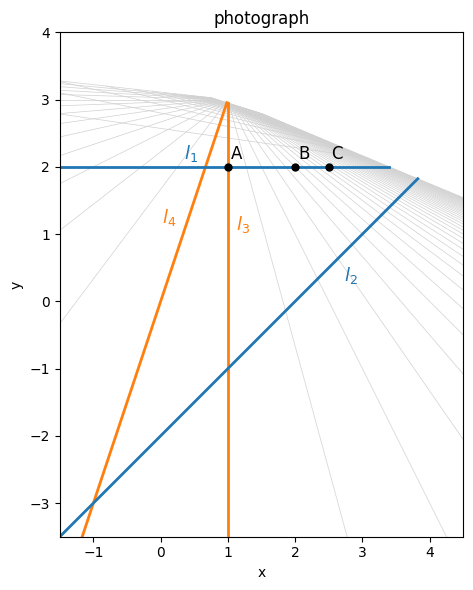

In [39]:
# Run to see Question 4 as a picture. Left: a floor of square tiles as the photograph shows it, with
# l1, l2 (blue), l3, l4 (orange) and the marks A, B, C. Right: the same floor after your H_P.
# Fill in HP in the cell above first; until then only the left panel is drawn.
G = np.array([[0.4, 0.75, 1.0],      # maps floor coordinates (X, Y, 1) to the photograph;
              [0.2, 2.25, 2.0],      # the tiles are 1 x 1 squares on the floor
              [0.1, 0.75, 1.0]])


def draw_floor(HP=None, X=range(-15, 41), Y=range(-6, 26)):
    # Tile edges X = const and Y = const, each cut to the part of the floor in front of the camera,
    # where the third coordinate G[2] @ (X, Y, 1) is positive.
    segs = []
    for x in X:
        y0 = max(Y[0], (0.02 - G[2, 2] - G[2, 0] * x) / G[2, 1])
        if y0 < Y[-1]:
            segs.append((("X", x), (x, y0), (x, Y[-1])))
    for y in Y:
        x0 = max(X[0], (0.02 - G[2, 2] - G[2, 1] * y) / G[2, 0])
        if x0 < X[-1]:
            segs.append((("Y", y), (x0, y), (X[-1], y)))
    # floor line -> (name, colour, floor point where the name is written, text offset)
    named = {("X", 0): ("$l_3$", "tab:orange", (0, -0.6), (6, -6)), ("X", -1): ("$l_4$", "tab:orange", (-1, -0.5), (-20, -6)),
             ("Y", 0): ("$l_1$", "tab:blue", (-1.5, 0), (-6, 6)), ("Y", -1): ("$l_2$", "tab:blue", (3, -1), (4, -16))}
    panels = [("photograph", G)] + ([("after $H_P$", HP @ G)] if HP is not None else [])
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 6), squeeze=False)
    for ax, (title, M) in zip(axes[0], panels):
        def img(x, y):
            p = M @ np.array([x, y, 1.0])
            return p[:2] / p[2]

        for k, a, b in segs:
            name, colour = named.get(k, (None, "0.82"))[:2]
            a, b = img(*a), img(*b)
            ax.plot([a[0], b[0]], [a[1], b[1]], color=colour, lw=2 if name else 0.5, zorder=2 if name else 1)
        for name, colour, at, offset in named.values():
            ax.annotate(name, img(*at), color=colour, fontsize=13, textcoords="offset points", xytext=offset)
        for name, x in (("A", 0), ("B", 5), ("C", 10)):
            p = img(x, 0)
            ax.plot(*p, "ko", ms=5, zorder=3)
            ax.annotate(name, p, textcoords="offset points", xytext=(2, 6), fontsize=12)
        if title == "photograph":
            ax.set_xlim(-1.5, 4.5)                      # the photograph is a finite window onto the floor
            ax.set_ylim(-3.5, 4.0)
            if HP is not None:
                xs = np.array(ax.get_xlim())
                ax.plot(xs, -(HP[2, 0] * xs + HP[2, 2]) / HP[2, 1], "r--", lw=1.2, label="vanishing line (last row of $H_P$)")
                ax.legend(loc="lower right")
        else:                                           # frame the tiles between l2, l4 and C
            box = np.array([img(x, y) for x in (-1, 10) for y in (-1, 3)])
            ax.set_xlim(box[:, 0].min() - 0.3, box[:, 0].max() + 0.3)
            ax.set_ylim(box[:, 1].min() - 0.3, box[:, 1].max() + 0.3)
        ax.set_aspect("equal")
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    plt.tight_layout()
    plt.show()


draw_floor(HP)

---
## Question 5. The camera model  [10 marks]

**(a) Projecting a point.** **[6]**

A camera has intrinsics $K$, rotation $R$ and centre $C$ (given in world coordinates):

$$
K=\begin{bmatrix}800&0&320\\0&800&240\\0&0&1\end{bmatrix},\qquad R=\begin{bmatrix}0&-1&0\\1&0&0\\0&0&1\end{bmatrix},\qquad C=(2,0,0)^{\top}.
$$

1. Compute $\mathbf{t}$ and the $3\times4$ camera matrix $P=K[R\mid\mathbf{t}]$. Project the world point $\mathbf{X}_w=(3,1,10)^{\top}$ to pixel coordinates. Check your answer by first computing the point in camera coordinates, $\mathbf{X}_c=R(\mathbf{X}_w-C)$.
2. Find the vanishing points of the world directions $(0,0,1)^{\top}$ and $(1,0,0)^{\top}$. One of them is not a finite pixel. What does this mean for how world lines in that direction look in the image?
3. What does $\mathbf{t}$ mean physically? Recover $C$ from $R$ and $\mathbf{t}$.

### Answer 5(a).

### 1. Translation Vector, Camera Matrix, and Point Projection

#### Computing $\mathbf{t}$

The translation vector expresses the world origin relative to the camera frame:

$$\mathbf{t} = -R C = -\begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 2 \\ 0 \\ 0 \end{bmatrix} = -\begin{bmatrix} 0 \\ 2 \\ 0 \end{bmatrix} = \begin{bmatrix} 0 \\ -2 \\ 0 \end{bmatrix}$$

---

#### Computing the Camera Matrix $P$

$$[R \mid \mathbf{t}] = \begin{bmatrix} 0 & -1 & 0 & 0 \\ 1 & 0 & 0 & -2 \\ 0 & 0 & 1 & 0 \end{bmatrix}$$

Multiplying by intrinsic matrix $K$:

$$P = K [R \mid \mathbf{t}] = \begin{bmatrix} 800 & 0 & 320 \\ 0 & 800 & 240 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 & -1 & 0 & 0 \\ 1 & 0 & 0 & -2 \\ 0 & 0 & 1 & 0 \end{bmatrix} = \begin{bmatrix} 0 & -800 & 320 & 0 \\ 800 & 0 & 240 & -1600 \\ 0 & 0 & 1 & 0 \end{bmatrix}$$

---

#### Projecting World Point $\mathbf{X}_w = (3, 1, 10)^T$

Using homogeneous coordinates $\tilde{\mathbf{X}}_w = \begin{bmatrix} 3 & 1 & 10 & 1 \end{bmatrix}^T$:

$$\mathbf{x} = P \tilde{\mathbf{X}}_w = \begin{bmatrix} 0 & -800 & 320 & 0 \\ 800 & 0 & 240 & -1600 \\ 0 & 0 & 1 & 0 \end{bmatrix} \begin{bmatrix} 3 \\ 1 \\ 10 \\ 1 \end{bmatrix} = \begin{bmatrix} -800(1) + 320(10) \\ 800(3) + 240(10) - 1600(1) \\ 1(10) \end{bmatrix} = \begin{bmatrix} 2400 \\ 3200 \\ 10 \end{bmatrix}$$

Converting from homogeneous to Euclidean pixel coordinates:

$$\begin{bmatrix} u \\ v \end{bmatrix} = \begin{bmatrix} \frac{2400}{10} \\ \frac{3200}{10} \end{bmatrix} = \mathbf{\begin{bmatrix} 240 \\ 320 \end{bmatrix}}$$

---

#### Verification via Camera Coordinates $\mathbf{X}_c$

$$\mathbf{X}_c = R(\mathbf{X}_w - C) = \begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \left( \begin{bmatrix} 3 \\ 1 \\ 10 \end{bmatrix} - \begin{bmatrix} 2 \\ 0 \\ 0 \end{bmatrix} \right) = \begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 1 \\ 10 \end{bmatrix} = \begin{bmatrix} -1 \\ 1 \\ 10 \end{bmatrix}$$

Projecting through intrinsics $K$:

$$\mathbf{x} = K \mathbf{X}_c = \begin{bmatrix} 800 & 0 & 320 \\ 0 & 800 & 240 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} -1 \\ 1 \\ 10 \end{bmatrix} = \begin{bmatrix} 800(-1) + 320(10) \\ 800(1) + 240(10) \\ 1(10) \end{bmatrix} = \begin{bmatrix} 2400 \\ 3200 \\ 10 \end{bmatrix} \implies \mathbf{\begin{bmatrix} 240 \\ 320 \end{bmatrix}}$$

Both approaches yield identical coordinates $(u, v) = (240, 320)$.

---

### 2. Vanishing Points of World Directions

A world direction vector $\mathbf{D}$ corresponds to a point at infinity $\mathbf{X}_\infty = \begin{bmatrix} \mathbf{D}^T & 0 \end{bmatrix}^T$. Its projection onto the image is given by:

$$\mathbf{v} = P \begin{bmatrix} \mathbf{D} \\ 0 \end{bmatrix} = K R \mathbf{D}$$

---

#### Direction $\mathbf{D}_1 = (0, 0, 1)^T$

$$R \mathbf{D}_1 = \begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix}$$

$$\mathbf{v}_1 = K (R \mathbf{D}_1) = \begin{bmatrix} 800 & 0 & 320 \\ 0 & 800 & 240 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} 320 \\ 240 \\ 1 \end{bmatrix} \implies \mathbf{(u, v) = (320, 240)}$$

This finite vanishing point lands directly on the principal point $(p_x, p_y) = (320, 240)$ because the world $Z$-axis aligns directly with the camera's optical/principal axis.

---

#### Direction $\mathbf{D}_2 = (1, 0, 0)^T$

$$R \mathbf{D}_2 = \begin{bmatrix} 0 & -1 & 0 \\ 1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 1 \\ 0 \\ 0 \end{bmatrix} = \begin{bmatrix} 0 \\ 1 \\ 0 \end{bmatrix}$$

$$\mathbf{v}_2 = K (R \mathbf{D}_2) = \begin{bmatrix} 800 & 0 & 320 \\ 0 & 800 & 240 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ 1 \\ 0 \end{bmatrix} = \begin{bmatrix} 0 \\ 800 \\ 0 \end{bmatrix} \sim \begin{bmatrix} \mathbf{0} \\ \mathbf{1} \\ \mathbf{0} \end{bmatrix}$$

#### Geometric Meaning of the Non-Finite Vanishing Point:

Because the third homogeneous coordinate is $w = 0$, $\mathbf{v}_2$ is an **ideal point (point at infinity)** in the image plane along the vertical direction.

* **Physical orientation:** The world direction $(1, 0, 0)^T$ maps to $(0, 1, 0)^T$ in camera coordinates, meaning it is **strictly parallel to the camera's image plane** (specifically along the camera's vertical $y$-axis).
* **Appearance in the image:** Lines parallel to $(1, 0, 0)^T$ in the 3D scene **do not converge** to a finite point in the photograph; they appear as mutually **parallel, vertical lines** across the image.

---

### 3. Physical Meaning of $\mathbf{t}$ and Recovery of $C$

* **Physical Meaning of $\mathbf{t}$:**
While $C$ represents the position of the camera center measured in the **world coordinate frame**, $\mathbf{t} = -R C$ represents the **position of the world coordinate origin expressed in the camera's reference frame**.
* **Recovering $C$ from $R$ and $\mathbf{t}$:**
Since $R$ is an orthogonal rotation matrix ($R^T R = I \implies R^{-1} = R^T$):

$$\mathbf{t} = -R C \implies R C = -\mathbf{t} \implies C = -R^T \mathbf{t}$$


Evaluating with the given values:

$$C = -\begin{bmatrix} 0 & 1 & 0 \\ -1 & 0 & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} 0 \\ -2 \\ 0 \end{bmatrix} = -\begin{bmatrix} -2 \\ 0 \\ 0 \end{bmatrix} = \mathbf{\begin{bmatrix} 2 \\ 0 \\ 0 \end{bmatrix}}$$

In [40]:
# Optional check for 5(a).
K = np.array([[800, 0, 320], [0, 800, 240], [0, 0, 1]], float)
R = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]], float)
Cw = np.array([2, 0, 0], float)
Xw = np.array([3, 1, 10], float)

# TODO (optional): t, P = K [R | t], the projection of Xw, and the two vanishing points P @ (d, 0).

**(b) Field of view and counting.** **[4]**

The sensor is $640$ pixels wide.

1. Compute the horizontal field of view of this camera, and the field of view if the focal length is doubled.
2. How many independent parameters does $P$ have? How many are still unknown once $K$ has been calibrated?

### Answer 5(b).

### 1. Horizontal Field of View (HFOV)

From the intrinsic matrix $K$, the focal length in horizontal pixel units is $f_x = 800$, and the principal point is centered at $c_x = 320 = \frac{W}{2}$ for sensor width $W = 640$.

The horizontal field of view $\theta_H$ is given by:

$$\theta_H = 2 \arctan\left(\frac{W}{2 f_x}\right)$$

#### Standard Focal Length ($f_x = 800$):

$$\theta_H = 2 \arctan\left(\frac{640}{2 \times 800}\right) = 2 \arctan\left(\frac{640}{1600}\right) = 2 \arctan(0.4)$$

$$\theta_H = 2 \times 21.8014^{\circ} \approx \mathbf{43.60^{\circ}} \quad (\approx 0.761 \text{ rad})$$

---

#### Doubled Focal Length ($f_x' = 2 \times 800 = 1600$):

$$\theta'_H = 2 \arctan\left(\frac{640}{2 \times 1600}\right) = 2 \arctan\left(\frac{640}{3200}\right) = 2 \arctan(0.2)$$

$$\theta'_H = 2 \times 11.3099^{\circ} \approx \mathbf{22.62^{\circ}} \quad (\approx 0.395 \text{ rad})$$

*(Note: Because the tangent function is non-linear, doubling the focal length narrows the field of view to slightly more than half its original value, rather than dividing it by exactly two).*

---

### 2. Parameter Counting for Camera Matrix $P$

* **Independent parameters in $P$:**
The projection matrix $P$ has dimensions $3 \times 4$, containing 12 entries. Because $P$ maps homogeneous 3D coordinates to homogeneous 2D coordinates, it is defined only up to an overall non-zero global scale factor ($\lambda P \sim P$).

$$\text{Degrees of Freedom (DoF)} = 12 - 1 = \mathbf{11\text{ independent parameters}}$$



*(Comprising 5 intrinsic parameters in $K$ and 6 extrinsic parameters in $[R \mid \mathbf{t}]$).*
* **Unknown parameters remaining once $K$ is calibrated:**
Calibrating $K$ fixes all internal camera parameters (focal lengths, principal point, and skew). The remaining unknown parameters are purely **extrinsic**—governing the camera pose relative to the world coordinate frame:
* **$3$ rotation parameters:** Orienting the camera in 3D space (e.g., 3 Euler angles or axis-angle vector from $R \in \mathrm{SO}(3)$).
* **$3$ translation parameters:** Position of the camera center in 3D space ($\mathbf{t}$ or $C \in \mathbb{R}^3$).


$$\text{Remaining unknowns} = 3 + 3 = \mathbf{6\text{ parameters}}$$

---
## Question 6. Homographies and calibration  [8 marks]

**(a) A camera that only rotates.** **[3]**

Take $K=\mathrm{diag}(f,f,1)$ with $f=800$ px, and a rotation by $\theta=5^{\circ}$ about the camera's $y$ axis,

$$
R=\begin{bmatrix}\cos\theta&0&\sin\theta\\0&1&0\\-\sin\theta&0&\cos\theta\end{bmatrix}.
$$

Compute $H=KRK^{-1}$ in terms of $f$ and $\theta$. Then find where the image points $(0,0)$ and $(320,0)$ move to (one decimal).

### Answer 6(a).

### 1. Computing $H = KRK^{-1}$

Given:

$$K = \begin{bmatrix} f & 0 & 0 \\ 0 & f & 0 \\ 0 & 0 & 1 \end{bmatrix}, \qquad K^{-1} = \begin{bmatrix} \frac{1}{f} & 0 & 0 \\ 0 & \frac{1}{f} & 0 \\ 0 & 0 & 1 \end{bmatrix}$$

Multiplying $R K^{-1}$:

$$R K^{-1} = \begin{bmatrix} \cos\theta & 0 & \sin\theta \\ 0 & 1 & 0 \\ -\sin\theta & 0 & \cos\theta \end{bmatrix} \begin{bmatrix} \frac{1}{f} & 0 & 0 \\ 0 & \frac{1}{f} & 0 \\ 0 & 0 & 1 \end{bmatrix} = \begin{bmatrix} \frac{\cos\theta}{f} & 0 & \sin\theta \\ 0 & \frac{1}{f} & 0 \\ -\frac{\sin\theta}{f} & 0 & \cos\theta \end{bmatrix}$$

Multiplying by $K$:

$$H = K (R K^{-1}) = \begin{bmatrix} f & 0 & 0 \\ 0 & f & 0 \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} \frac{\cos\theta}{f} & 0 & \sin\theta \\ 0 & \frac{1}{f} & 0 \\ -\frac{\sin\theta}{f} & 0 & \cos\theta \end{bmatrix} = \mathbf{\begin{bmatrix} \cos\theta & 0 & f\sin\theta \\ 0 & 1 & 0 \\ -\frac{\sin\theta}{f} & 0 & \cos\theta \end{bmatrix}}$$

---

### 2. Numerical Values with $f = 800$ and $\theta = 5^{\circ}$

Evaluating trigonometric terms for $\theta = 5^{\circ}$:

* $\cos 5^{\circ} \approx 0.996195$
* $\sin 5^{\circ} \approx 0.087156$
* $f\sin 5^{\circ} = 800 \times 0.087156 \approx 69.7246$
* $-\frac{\sin 5^{\circ}}{f} = -\frac{0.087156}{800} \approx -0.000108945$

$$H \approx \begin{bmatrix} 0.996195 & 0 & 69.7246 \\ 0 & 1 & 0 \\ -0.000108945 & 0 & 0.996195 \end{bmatrix}$$

---

### 3. Transforming Image Points

For any point $(x, y)$, its homogeneous representation transforms via $\tilde{\mathbf{x}}' = H \begin{bmatrix} x & y & 1 \end{bmatrix}^T$:

$$\tilde{\mathbf{x}}' = \begin{bmatrix} x\cos\theta + f\sin\theta \\ y \\ -x\frac{\sin\theta}{f} + \cos\theta \end{bmatrix}$$

Inhomogeneous image coordinates are given by $\left(x', y'\right) = \left(\frac{x\cos\theta + f\sin\theta}{\cos\theta - x\frac{\sin\theta}{f}}, \, \frac{y}{\cos\theta - x\frac{\sin\theta}{f}}\right) = \left(\frac{x + f\tan\theta}{1 - \frac{x}{f}\tan\theta}, \, \frac{\frac{y}{\cos\theta}}{1 - \frac{x}{f}\tan\theta}\right)$.

---

#### Point 1: $(0, 0)$

$$\tilde{\mathbf{x}}'_1 = H \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} f\sin\theta \\ 0 \\ \cos\theta \end{bmatrix} = \begin{bmatrix} 69.7246 \\ 0 \\ 0.996195 \end{bmatrix}$$

$$x'_1 = \frac{f\sin\theta}{\cos\theta} = f\tan 5^{\circ} = 800 \times \tan 5^{\circ} \approx 800 \times 0.0874887 = 69.991 \dots \approx \mathbf{70.0}$$

$$y'_1 = \frac{0}{0.996195} = \mathbf{0.0}$$

* Transformed position: **$(70.0, 0.0)$**

---

#### Point 2: $(320, 0)$

$$\tilde{\mathbf{x}}'_2 = H \begin{bmatrix} 320 \\ 0 \\ 1 \end{bmatrix} = \begin{bmatrix} 320(0.996195) + 69.7246 \\ 0 \\ -320(0.000108945) + 0.996195 \end{bmatrix} = \begin{bmatrix} 318.7823 + 69.7246 \\ 0 \\ -0.034862 + 0.996195 \end{bmatrix} = \begin{bmatrix} 388.5069 \\ 0 \\ 0.961333 \end{bmatrix}$$

$$x'_2 = \frac{388.5069}{0.961333} \approx 404.134 \dots \approx \mathbf{404.1}$$

$$y'_2 = \mathbf{0.0}$$

* Transformed position: **$(404.1, 0.0)$**

**(b) How many RANSAC iterations.** **[2]**

For confidence $p$ and inlier fraction $w$, the number of random samples of size $n$ needed is $N=\log(1-p)/\log(1-w^n)$.

1. Compute $N$ for $p=0.99$, $n=4$ and $w=0.5$, and again for $w=0.2$.
2. Eight correspondences would give a better-conditioned DLT than four. Why do we still draw samples of only four? Support your answer with $N$ for $n=8$, $w=0.5$.

### Answer 6(b).

### 1. Calculation of $N$ ($p=0.99, n=4$)

The formula for the number of RANSAC iterations is:

$$N = \frac{\log(1 - p)}{\log(1 - w^n)}$$

With $p = 0.99$, the numerator is:


$$\log(1 - 0.99) = \log(0.01) \approx -4.60517$$

---

#### Case 1: $w = 0.5$ (50% inliers)

The probability of drawing an all-inlier sample of size $4$ is:


$$w^n = (0.5)^4 = 0.0625 = \frac{1}{16}$$

$$N = \frac{\log(0.01)}{\log(1 - 0.0625)} = \frac{\log(0.01)}{\log(0.9375)} \approx \frac{-4.60517}{-0.06454} \approx \mathbf{71.36} \implies \mathbf{72\text{ iterations}}$$

---

#### Case 2: $w = 0.2$ (20% inliers)

The probability of drawing an all-inlier sample of size $4$ is:


$$w^n = (0.2)^4 = 0.0016 = \frac{1}{625}$$

$$N = \frac{\log(0.01)}{\log(1 - 0.0016)} = \frac{\log(0.01)}{\log(0.9984)} \approx \frac{-4.60517}{-0.001601} \approx \mathbf{2875.93} \implies \mathbf{2876\text{ iterations}}$$

---

### 2. Why RANSAC Uses Minimal Samples ($n=4$)

RANSAC samples must be **uncontaminated** (containing zero outliers) to generate a valid model hypothesis. The probability that all $n$ points in a randomly selected subset are inliers is $w^n$, which **decays exponentially** with the sample size $n$.

#### Iterations Required for $n = 8$ and $w = 0.5$:

$$w^n = (0.5)^8 = \frac{1}{256} \approx 0.00390625$$

$$N = \frac{\log(0.01)}{\log(1 - 0.5^8)} = \frac{\log(0.01)}{\log(1 - 0.00390625)} \approx \frac{-4.60517}{-0.0039139} \approx \mathbf{1176.62} \implies \mathbf{1177\text{ iterations}}$$

#### Comparison and Practical Workflow:

* Increasing the sample size from $n = 4$ to $n = 8$ causes the required iterations to jump from **$72$ to $1177$** (a **$16\times$ computational increase**), even under a clean $50\%$ inlier scenario. If inliers drop to $20\%$, $n = 8$ would require over $1.8 \times 10^7$ iterations.
* In standard vision pipelines, the minimal sample size ($n=4$) is used strictly to **hypothesize** a model and identify the consensus set of inliers. Once the full set of inliers is isolated, the homography is **re-estimated via overdetermined DLT / Levenberg-Marquardt on all found inliers**, providing optimal conditioning and numerical precision without paying the exponential sampling cost during the search phase.

**(c) Reading a pose off a homography.** **[3]**

A checkerboard lying in the plane $Z=0$ is photographed by the camera of Question 5, $K=\begin{bmatrix}800&0&320\\0&800&240\\0&0&1\end{bmatrix}$, and the normalised DLT gives

$$
H=\begin{bmatrix}1600&384&3200\\0&1568&2400\\0&1.2&10\end{bmatrix}.
$$

1. Recover $\lambda$, $\mathbf r_1$, $\mathbf r_2$, $\mathbf r_3$ and $\mathbf{t}$. Check that $\mathbf r_1^{\top}\mathbf r_2=0$ and $\lVert\mathbf r_1\rVert=\lVert\mathbf r_2\rVert$.
2. Why must the board be tilted, and not just moved, between the views used to calibrate $K$?

### Answer 6(c).

### 1. Recovering Pose from the Homography

A planar checkerboard lying on the world plane $Z = 0$ has points $\mathbf{X}_w = \begin{bmatrix} X & Y & 0 & 1 \end{bmatrix}^T$.

Projecting these points through camera matrix $P = K \begin{bmatrix} \mathbf{r}_1 & \mathbf{r}_2 & \mathbf{r}_3 & \mathbf{t} \end{bmatrix}$:

$$\mathbf{x} \sim P \begin{bmatrix} X \\ Y \\ 0 \\ 1 \end{bmatrix} = K \begin{bmatrix} \mathbf{r}_1 & \mathbf{r}_2 & \mathbf{t} \end{bmatrix} \begin{bmatrix} X \\ Y \\ 1 \end{bmatrix}$$

Thus, the homography matrix relates to the camera pose by:

$$H = \lambda K \begin{bmatrix} \mathbf{r}_1 & \mathbf{r}_2 & \mathbf{t} \end{bmatrix} \implies K^{-1} H = \lambda \begin{bmatrix} \mathbf{r}_1 & \mathbf{r}_2 & \mathbf{t} \end{bmatrix}$$

---

#### Computing $K^{-1} H$

Given $K$:


$$K^{-1} = \begin{bmatrix} \frac{1}{800} & 0 & -\frac{320}{800} \\ 0 & \frac{1}{800} & -\frac{240}{800} \\ 0 & 0 & 1 \end{bmatrix} = \begin{bmatrix} 0.00125 & 0 & -0.4 \\ 0 & 0.00125 & -0.3 \\ 0 & 0 & 1 \end{bmatrix}$$

Multiplying $K^{-1}$ by each column of $H = \begin{bmatrix} \mathbf{h}_1 & \mathbf{h}_2 & \mathbf{h}_3 \end{bmatrix}$:

* **First column ($K^{-1}\mathbf{h}_1$):**

$$K^{-1} \begin{bmatrix} 1600 \\ 0 \\ 0 \end{bmatrix} = \begin{bmatrix} \frac{1600}{800} - 0.4(0) \\ 0 - 0.3(0) \\ 0 \end{bmatrix} = \begin{bmatrix} 2 \\ 0 \\ 0 \end{bmatrix}$$


* **Second column ($K^{-1}\mathbf{h}_2$):**

$$K^{-1} \begin{bmatrix} 384 \\ 1568 \\ 1.2 \end{bmatrix} = \begin{bmatrix} \frac{384}{800} - 0.4(1.2) \\ \frac{1568}{800} - 0.3(1.2) \\ 1.2 \end{bmatrix} = \begin{bmatrix} 0.48 - 0.48 \\ 1.96 - 0.36 \\ 1.2 \end{bmatrix} = \begin{bmatrix} 0 \\ 1.6 \\ 1.2 \end{bmatrix}$$


* **Third column ($K^{-1}\mathbf{h}_3$):**

$$K^{-1} \begin{bmatrix} 3200 \\ 2400 \\ 10 \end{bmatrix} = \begin{bmatrix} \frac{3200}{800} - 0.4(10) \\ \frac{2400}{800} - 0.3(10) \\ 10 \end{bmatrix} = \begin{bmatrix} 4 - 4 \\ 3 - 3 \\ 10 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \\ 10 \end{bmatrix}$$



$$K^{-1} H = \begin{bmatrix} 2 & 0 & 0 \\ 0 & 1.6 & 0 \\ 0 & 1.2 & 10 \end{bmatrix}$$

---

#### Recovering $\lambda$, Rotation Columns, and Translation

Since $\mathbf{r}_1$ must be a unit vector ($\lVert\mathbf{r}_1\rVert = 1$):

$$\lambda = \lVert K^{-1}\mathbf{h}_1 \rVert = \sqrt{2^2 + 0^2 + 0^2} = \mathbf{2} \quad \left(\text{or scale factor } \frac{1}{\lambda} = 0.5\right)$$

Dividing the columns of $K^{-1}H$ by $\lambda = 2$:

* **First rotation column:**

$$\mathbf{r}_1 = \frac{1}{2} \begin{bmatrix} 2 \\ 0 \\ 0 \end{bmatrix} = \mathbf{\begin{bmatrix} 1 \\ 0 \\ 0 \end{bmatrix}}$$


* **Second rotation column:**

$$\mathbf{r}_2 = \frac{1}{2} \begin{bmatrix} 0 \\ 1.6 \\ 1.2 \end{bmatrix} = \mathbf{\begin{bmatrix} 0 \\ 0.8 \\ 0.6 \end{bmatrix}}$$


* **Third rotation column (orthonormal right-handed system $\mathbf{r}_3 = \mathbf{r}_1 \times \mathbf{r}_2$):**

$$\mathbf{r}_3 = \begin{bmatrix} 1 \\ 0 \\ 0 \end{bmatrix} \times \begin{bmatrix} 0 \\ 0.8 \\ 0.6 \end{bmatrix} = \begin{bmatrix} (0)(0.6) - (0)(0.8) \\ (0)(0) - (1)(0.6) \\ (1)(0.8) - (0)(0) \end{bmatrix} = \mathbf{\begin{bmatrix} 0 \\ -0.6 \\ 0.8 \end{bmatrix}}$$


* **Translation vector:**

$$\mathbf{t} = \frac{1}{2} \begin{bmatrix} 0 \\ 0 \\ 10 \end{bmatrix} = \mathbf{\begin{bmatrix} 0 \\ 0 \\ 5 \end{bmatrix}}$$



---

#### Verification of Orthonormality Constraints:

* **Orthogonality:**

$$\mathbf{r}_1^{\top}\mathbf{r}_2 = (1)(0) + (0)(0.8) + (0)(0.6) = \mathbf{0}$$


* **Equal unit norms:**

$$\lVert\mathbf{r}_1\rVert = \sqrt{1^2 + 0^2 + 0^2} = \mathbf{1}$$


$$\lVert\mathbf{r}_2\rVert = \sqrt{0^2 + 0.8^2 + 0.6^2} = \sqrt{0.64 + 0.36} = \sqrt{1} = \mathbf{1}$$


$$\lVert\mathbf{r}_1\rVert = \lVert\mathbf{r}_2\rVert = 1$$



---

### 2. Why the Calibration Board Must Be Tilted

In planar camera calibration (Zhang's method), each homography provides two independent linear constraints on the Image of the Absolute Conic (IAC), $\omega = K^{-\top} K^{-1}$:

$$\mathbf{h}_1^{\top} \omega \mathbf{h}_2 = 0 \qquad \text{and} \qquad \mathbf{h}_1^{\top} \omega \mathbf{h}_1 = \mathbf{h}_2^{\top} \omega \mathbf{h}_2$$

These constraints depend strictly on the orientation columns $\mathbf{r}_1$ and $\mathbf{r}_2$ of the rotation matrix $R$, and are **independent of the translation $\mathbf{t}$** ($\mathbf{h}_1 = \lambda K \mathbf{r}_1$ and $\mathbf{h}_2 = \lambda K \mathbf{r}_2$).

* **If the board is only translated:** The rotation matrix $R$ remains completely unchanged between views. As a result, every translated image produces the exact same two equations on $\omega$, providing **zero new independent constraints** on the camera intrinsics.
* **Why tilting (out-of-plane rotation) is necessary:** Tilting the calibration target changes the plane normal relative to the camera frame, varying the directions of $\mathbf{r}_1$ and $\mathbf{r}_2$ in 3D space. This generates genuinely independent linear equations, allowing the 5 unknown parameters of $\omega$ (and thus $K$) to be uniquely determined.

In [41]:
# Optional check for 6(c).
Hb = np.array([[1600, 384, 3200],
               [0, 1568, 2400],
               [0, 1.2, 10]], float)

# TODO (optional): M = K^-1 Hb, lambda from the column norms, then r1, r2, r3 = r1 x r2 and t.

---
# Part B - Programming  [40 marks]

## Question 7. Panorama stitching  [40 marks]

You will build a panorama from your own photographs. You write the main steps yourself: the DLT, RANSAC, and a backward warp with bilinear interpolation. SIFT and the matching are given.

**Data.** Take **three to five** overlapping photographs. Stand in one spot and *turn* the camera (do not walk), so that neighbouring photos overlap by about $30$-$50\%$. Keep the exposure fixed if your phone allows it. The code shrinks each image so that its longer side is at most $1000$ px. Put the photographs in the zip.

**Starter code.** The cells below hold the starter code, split by part. Loading the images, SIFT, matching, the figures and the driver `run_pipeline` are already written. Fill in every function marked `TODO` and do not change anything else, so that the pipeline runs end to end. The setup cell downloaded `assignment3_data/`, which has sample photographs and the outputs that the finished code gives on them (`assignment3_data/sample_output/`). Get your code working on the sample data first, then run it on your own photographs for the report.

**Reproducibility.** Draw every random sample from the global generator `RNG` (for example `RNG.choice(m, 4, replace=False)`). `run_pipeline` re-seeds it, so if your code does the same steps as the reference code, your numbers match the sample `report.txt` exactly. Small differences are fine.

**You may use from OpenCV:** reading, writing, colour conversion and resizing of images; `cv2.SIFT_create` for keypoints and descriptors; `cv2.BFMatcher` with `knnMatch`; `cv2.drawMatches` for figures; and `cv2.findHomography` *only* for the comparison in part (c).

**You must write yourself:** Hartley normalisation, the DLT, RANSAC, chaining the homographies, the canvas size, the backward warp with bilinear interpolation, and the compositing. Do not use `cv2.warpPerspective`, `cv2.remap`, `cv2.Stitcher`, `cv2.perspectiveTransform` or `skimage.transform`. Use vectorised NumPy; a Python loop over pixels is too slow.

In [3]:
RNG = np.random.default_rng(0)

### (a) Features and matches  [5 marks]

Find SIFT keypoints and descriptors in each image. For each pair of neighbouring images, find the $k=2$ nearest neighbours of every descriptor, and keep a match only if it passes Lowe's ratio test at $0.8$. `run_pipeline` prints the number of keypoints per image and, for each pair, the number of matches before and after the ratio test, and draws the matches for one pair.

**To do:** `match_pair`.

In [4]:
def load_images(paths, max_side):
    """Read, and downscale so the longer side is at most max_side."""
    ims = []
    for p in paths:
        im = cv2.imread(p, cv2.IMREAD_COLOR)
        if im is None:
            raise FileNotFoundError(f"cannot read {p}")
        s = max_side / max(im.shape[:2])
        if s < 1:
            im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        ims.append(im)
    return ims


def sift_features(im):
    sift = cv2.SIFT_create()
    kp, des = sift.detectAndCompute(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), None)
    return kp, des


def match_pair(des1, des2, ratio=0.8):
    """Lowe's ratio test on the two nearest neighbours. Returns the cv2.DMatch
    list that survives and the number of putative (k=1) matches."""
    bf = cv2.BFMatcher(cv2.NORM_L2)
    knn = bf.knnMatch(des1, des2, k=2)
    # (a): keep a match m only if m.distance < ratio * (second-best distance)
    good = []
    for match in knn:
      if len(match) == 2:
        m, n = match
        if m.distance < ratio * n.distance:
          good.append(m)
    return good, len(knn)

def match_points(kp1, kp2, matches):
    src = np.float64([kp1[m.queryIdx].pt for m in matches])
    dst = np.float64([kp2[m.trainIdx].pt for m in matches])
    return src, dst

### (b) Normalised DLT  [8 marks]

Write `dlt(src, dst)`. It takes $m\ge4$ correspondences and

1. normalises each point set so that its centroid is at the origin and the mean distance from the centroid is $\sqrt2$ (Hartley normalisation);
2. builds the $2m\times9$ matrix $A$, two rows per correspondence;
3. takes the last right singular vector of $A$ and reshapes it to $3\times3$, which gives $\hat H$;
4. undoes the normalisation: $H=T_{\text{dst}}^{-1}\hat H\,T_{\text{src}}$.

Test it with the cell below, which uses four exact synthetic correspondences made from a known $H$: after scaling both to $h_{33}=1$, the largest entry-wise difference should be about $10^{-10}$ or smaller. `run_pipeline` then runs the DLT with and without normalisation on the RANSAC inliers of one real pair, and prints for both the mean reprojection error on the inliers and the conditioning ratio $\sigma_1/\sigma_8$ of $A$.

**To do:** `normalise_points`, `dlt_system`, `dlt` (and `reprojection_errors`, which is used in part (c)).

In [5]:
def to_h(p):
    """(n,2) -> (n,3) homogeneous."""
    return np.hstack([p, np.ones((len(p), 1))])


def from_h(ph):
    return ph[:, :2] / ph[:, 2:3]


def transfer(H, p):
    """Apply H to (n,2) points and dehomogenise."""
    return from_h(to_h(p) @ H.T)


def normalise_points(p):
    """Hartley: translate so the centroid is at the origin, scale so the mean
    distance from it is sqrt(2). Returns the (n,2) normalised points and the
    3x3 matrix T that does it (normalised = T applied to the originals)."""
    # (b)
    centroid = np.mean(p, axis=0)
    dists = np.linalg.norm(p - centroid, axis=1)
    mean_dist = np.mean(dists)
    scale = np.sqrt(2.0) / mean_dist if mean_dist > 1e-12 else 1.0
    cx, cy = centroid
    T = np.array([
        [scale, 0.0,   -scale * cx],
        [0.0,   scale, -scale * cy],
        [0.0,   0.0,    1.0       ]
    ], dtype=np.float64)
    p_norm = transfer(T, p)
    return p_norm, T


def dlt_system(src, dst, normalise=True):
    """The 2m x 9 matrix A of the DLT, two rows per correspondence, built on the
    normalised points, together with the two normalising transforms Ts, Td."""
    if normalise:
        s, Ts = normalise_points(src)
        d, Td = normalise_points(dst)
    else:
        s, d, Ts, Td = src, dst, np.eye(3), np.eye(3)
    # (b): for correspondence (xs,ys) -> (xt,yt) the two rows are
    #   [-xs, -ys, -1,   0,   0,  0,  xs*xt, ys*xt, xt]
    #   [  0,   0,  0, -xs, -ys, -1,  xs*yt, ys*yt, yt]
    m = len(src)
    xs, ys = s[:, 0], s[:, 1]
    xt, yt = d[:, 0], d[:, 1]
    ones = np.ones(m)
    zeros = np.zeros(m)
    row1 = np.column_stack([-xs, -ys, -ones, zeros, zeros, zeros, xs * xt, ys * xt, xt])
    row2 = np.column_stack([zeros, zeros, zeros, -xs, -ys, -ones, xs * yt, ys * yt, yt])
    A = np.empty((2 * m, 9), dtype=np.float64)
    A[0::2] = row1
    A[1::2] = row2
    return A, Ts, Td


def dlt(src, dst, normalise=True):
    """H with dst ~ H src from m >= 4 correspondences: the last right singular
    vector of A, reshaped 3x3, then denormalised as H = Td^-1 Hn Ts.
    Return it scaled so that ||H||_F = 1."""
    A, Ts, Td = dlt_system(src, dst, normalise)
    #  (b)
    _, _, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3, 3)
    # Denormalise
    H = np.linalg.inv(Td) @ Hn @ Ts
    # Normalise so ||H||_F = 1
    H = H / np.linalg.norm(H, 'fro')
    return H


def dlt_singular_values(src, dst, normalise=True):
    return np.linalg.svd(dlt_system(src, dst, normalise)[0], compute_uv=False)


def reprojection_errors(H, src, dst):
    """Euclidean distance in pixels between H(src_i) and dst_i, shape (m,)."""
    #  (c)
    mapped_src = transfer(H, src)
    return np.linalg.norm(mapped_src - dst, axis=1)


def synthetic_dlt_test():
    """Four exact correspondences from a known H must return it to ~1e-10.
    Given: use it to check your dlt() before touching real data."""
    H_true = np.array([[1.2, 0.1, 30.0], [-0.05, 0.9, -12.0], [1e-4, -2e-4, 1.0]])
    src = RNG.uniform(0, 800, (4, 2))
    dst = transfer(H_true, src)
    H = dlt(src, dst)
    err = np.abs(H / H[2, 2] - H_true / H_true[2, 2]).max()
    return err

In [6]:
# Check your DLT before touching real data: this should print a number around 1e-10 or smaller.
print(f"synthetic DLT test: {synthetic_dlt_test():.2e}")

synthetic DLT test: 2.63e-13


### (c) RANSAC  [8 marks]

Write `ransac(src, dst, tol, p)`. In each iteration it

1. draws four correspondences at random, and skips the sample if three of its points lie (nearly) on a line;
2. fits $H$ to the four with your DLT;
3. computes the reprojection error $\varepsilon_i=\lVert\mathbf{x}'_i-H\mathbf{x}_i\rVert$ in pixels for every correspondence, and counts the inliers ($\varepsilon_i<$ `tol`);
4. keeps the largest set of inliers found so far.

Set the number of iterations adaptively from $N=\log(1-p)/\log(1-w^4)$ with $p=0.99$, where $w$ is the best inlier fraction so far. At the end, fit $H$ again on all the inliers.

**To do:** `degenerate`, `ransac`.

In [7]:
def degenerate(p, tol=1e-3):
    """True if any three of the four points are (nearly) collinear. One way:
    the area of every triangle formed by three of them, relative to the squared
    spread of the points, is below tol."""
    #  (c)
    # Check all 4 triplets of points: (0,1,2), (0,1,3), (0,2,3), (1,2,3)
    triplets = [(0, 1, 2), (0, 1, 3), (0, 2, 3), (1, 2, 3)]

    # Measure point spread using variance / bounding dimension
    spread_sq = np.var(p, axis=0).sum()
    if spread_sq < 1e-12:
        return True

    for i, j, k in triplets:
        # Twice triangle area = |det([p_j - p_i, p_k - p_i])|
        v1 = p[j] - p[i]
        v2 = p[k] - p[i]
        area = 0.5 * np.abs(v1[0] * v2[1] - v1[1] * v2[0])
        # Collinear if normalized area is below tolerance
        if (area / spread_sq) < tol:
            return True

    return False


def ransac(src, dst, tol=3.0, p=0.99, max_iter=5000, min_iter=50):
    """Random four-point samples, consensus by reprojection error < tol pixels,
    adaptive iteration count N = log(1-p)/log(1-w^4) updated from the best
    inlier fraction w so far, then a refit of H on all inliers.
    Returns H, a boolean inlier mask, and the number of iterations run."""
    m = len(src)
    if m < 4:
        raise ValueError("need at least four correspondences")
    best_inl = np.zeros(m, bool)
    best_count = 0
    N, it = max_iter, 0
    while it < N:
        it += 1
        # (c): draw 4 distinct indices, skip degenerate samples, fit H,
        # count inliers, keep the best consensus and update N (keep it within
        # [min_iter, max_iter] and guard the log against w = 1 and w -> 0)

        # 1. Draw 4 distinct points using global generator RNG
        idx = RNG.choice(m, 4, replace=False)
        sample_src = src[idx]
        sample_dst = dst[idx]

        # Skip degenerate sample (if points are collinear in src or dst)
        if degenerate(sample_src) or degenerate(sample_dst):
            continue

        # 2. Fit H using minimal DLT
        try:
            H_cand = dlt(sample_src, sample_dst, normalise=True)
        except np.linalg.LinAlgError:
            continue

        # 3. Compute reprojection errors across all correspondences
        errs = reprojection_errors(H_cand, src, dst)
        inl = errs < tol
        count = np.sum(inl)

        # 4. Update best consensus set
        if count > best_count:
            best_count = count
            best_inl = inl

            # Update adaptive iteration bound N = log(1-p) / log(1 - w^4)
            w = best_count / m
            if w >= 1.0:
                N = min_iter
            else:
                w4 = w**4
                if w4 > 1e-12:
                    N_est = np.log(1.0 - p) / np.log(1.0 - w4)
                    N = int(np.clip(np.ceil(N_est), min_iter, max_iter))

    #  (c): refit on all inliers and recompute the consensus of the refit
    # Refit H on all discovered inliers (fallback to best 4 sample if < 4 inliers)
    if best_count >= 4:
        H = dlt(src[best_inl], dst[best_inl], normalise=True)
        # Recompute final consensus with the refitted H
        final_errs = reprojection_errors(H, src, dst)
        inl = final_errs < tol
    else:
        H = np.eye(3)
        inl = best_inl

    return H, inl, it

### (d) Warping and compositing  [12 marks]

1. Use the middle image as the reference. Chain the pairwise homographies to get $H_{i\to\text{ref}}$ for every image.
2. Map the four corners of every image into the reference frame and take the bounding box: this is the canvas. Build a translation that moves the top-left corner of the box to $(0,0)$.
3. For each canvas pixel, map it *backwards* through $H_{i\to\text{ref}}^{-1}$ into image $i$, and read the colour by bilinear interpolation of the four neighbouring pixels. Leave pixels that fall outside image $i$ empty.
4. Combine the warped images: at each canvas pixel, take either the median over the images that cover it, or a distance-weighted (feathered) average.

**To do:** `chain_to_reference`, `canvas_extent`, `warp_backward`, `composite`.

In [8]:
def chain_to_reference(H_pair, ref):
    """H_pair[i] maps image i -> image i+1. Return a list H_to_ref with
    H_to_ref[i] mapping image i -> the reference frame (H_to_ref[ref] = I).
    Chain outwards from the reference; on the right you need inverses."""
    n = len(H_pair) + 1
    H = [None] * n
    H[ref] = np.eye(3)
    #  (d)
    # Images to the left of ref: i < ref
    for i in range(ref - 1, -1, -1):
        H[i] = H[i + 1] @ H_pair[i]

    # Images to the right of ref: i > ref
    for i in range(ref + 1, n):
        H[i] = H[i - 1] @ np.linalg.inv(H_pair[i - 1])
    return H


def canvas_extent(ims, H_to_ref):
    """Transfer the four corners of every image into the reference frame, take
    the bounding box, and return the translation T that moves its top-left
    corner to (0,0) together with the canvas size (width, height)."""
    #  (d)
    all_corners = []
    for im, H in zip(ims, H_to_ref):
        h, w = im.shape[:2]
        # (x, y) corners of image: (0, 0), (w, 0), (w, h), (0, h)
        corners = np.array([
            [0.0, 0.0],
            [w,   0.0],
            [w,   h  ],
            [0.0, h  ]
        ], dtype=np.float64)
        corners_ref = transfer(H, corners)
        all_corners.append(corners_ref)

    all_corners = np.vstack(all_corners)
    min_x, min_y = np.min(all_corners, axis=0)
    max_x, max_y = np.max(all_corners, axis=0)

    # Translation shifting bounding box origin (min_x, min_y) to (0, 0)
    T = np.array([
        [1.0, 0.0, -min_x],
        [0.0, 1.0, -min_y],
        [0.0, 0.0,  1.0  ]
    ], dtype=np.float64)

    width = int(np.ceil(max_x - min_x))
    height = int(np.ceil(max_y - min_y))
    size = (width,height)
    return T, size


def warp_backward(im, H, size):
    """Warp im onto a (W,H) canvas so that canvas = H(image). For every canvas
    pixel map it back through H^-1, read the source by bilinear interpolation
    of its four neighbours (weights (1-d1)(1-d2), d1(1-d2), (1-d1)d2, d1 d2),
    and mark pixels that fall outside the source as invalid.
    Returns the warped image as float32 (H,W,3) and a boolean mask (H,W).
    Vectorise with np.meshgrid; a Python loop over pixels is too slow."""
    W, Hh = size
    # TODO
    h_src, w_src = im.shape[:2]

    # Canvas integer pixel grid
    x_c, y_c = np.meshgrid(np.arange(W), np.arange(Hh))
    coords_c = np.stack([x_c.ravel(), y_c.ravel()], axis=-1)  # (Hh*W, 2)

    # Inverse mapping from canvas coordinates back to source image
    H_inv = np.linalg.inv(H)
    coords_s = transfer(H_inv, coords_c)  # (Hh*W, 2)
    xs = coords_s[:, 0].reshape(Hh, W)
    ys = coords_s[:, 1].reshape(Hh, W)

    # Top-left integer neighbour (floor)
    x0 = np.floor(xs).astype(np.int64)
    y0 = np.floor(ys).astype(np.int64)
    x1 = x0 + 1
    y1 = y0 + 1

    # Inlier/validity mask: all four interpolation neighbours must lie inside im
    mask = (x0 >= 0) & (x1 < w_src) & (y0 >= 0) & (y1 < h_src)

    # Bilinear interpolation sub-pixel fractional offsets
    d1 = xs - x0  # dx
    d2 = ys - y0  # dy

    # Weights: w00=(1-d1)(1-d2), w10=d1(1-d2), w01=(1-d1)d2, w11=d1*d2
    w00 = ((1.0 - d1) * (1.0 - d2))[..., np.newaxis]
    w10 = (d1 * (1.0 - d2))[..., np.newaxis]
    w01 = ((1.0 - d1) * d2)[..., np.newaxis]
    w11 = (d1 * d2)[..., np.newaxis]

    # Clip indices to prevent index out of bounds on the full array
    x0_c = np.clip(x0, 0, w_src - 1)
    x1_c = np.clip(x1, 0, w_src - 1)
    y0_c = np.clip(y0, 0, h_src - 1)
    y1_c = np.clip(y1, 0, h_src - 1)

    # Read pixel values for all 4 corners
    im_f = im.astype(np.float32)
    p00 = im_f[y0_c, x0_c]
    p10 = im_f[y0_c, x1_c]
    p01 = im_f[y1_c, x0_c]
    p11 = im_f[y1_c, x1_c]

    out = w00 * p00 + w10 * p10 + w01 * p01 + w11 * p11
    # Zero out pixels outside the source boundaries
    out[~mask] = 0.0
    out = out.reshape(Hh, W, 3)
    mask = mask.reshape(Hh, W)
    return out, mask


def feather_weight(mask):
    """Distance to the nearest invalid pixel, so seams fade instead of cut."""
    d = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)
    return d / max(d.max(), 1e-6)


def composite(warped, masks, mode="median"):
    """Combine the warped images. 'median': per-pixel median over the images
    that cover the pixel. 'feather': weighted mean with feather_weight."""
    stack = np.stack(warped)                                   # (n,H,W,3)
    M = np.stack(masks)                                        # (n,H,W)
    #  (d)
    n, Hh, W, C = stack.shape

    out = np.zeros((Hh, W, C), dtype=np.float32)

    if mode == "median":
        # Create a float copy with NaN at invalid locations to use np.nanmedian
        stack_nan = stack.copy()
        stack_nan[~M[..., np.newaxis].repeat(C, axis=-1)] = np.nan

        # Suppress RuntimeWarning on pixels covered by 0 images (all NaN)
        with np.errstate(all='ignore'):
            med = np.nanmedian(stack_nan, axis=0)

        valid_any = np.any(M, axis=0)
        out[valid_any] = med[valid_any]

    elif mode == "feather":
        weights = np.stack([feather_weight(m) for m in masks])  # (n, H, W)
        weights_3d = weights[..., np.newaxis]                   # (n, H, W, 1)

        weighted_sum = np.sum(stack * weights_3d, axis=0)       # (H, W, 3)
        weight_total = np.sum(weights_3d, axis=0)               # (H, W, 1)

        valid = weight_total > 1e-6
        np.divide(weighted_sum, weight_total, out=out, where=valid)

    else:
        raise ValueError(f"Unknown compositing mode: {mode}")
    return np.clip(out, 0, 255).astype(np.uint8)

### Figures and the driver (given, do not change)

In [9]:
def draw_inliers(im1, im2, src, dst, inl):
    """Side by side, inliers green and outliers red."""
    h = max(im1.shape[0], im2.shape[0])
    out = np.zeros((h, im1.shape[1] + im2.shape[1], 3), np.uint8)
    out[:im1.shape[0], :im1.shape[1]] = im1
    out[:im2.shape[0], im1.shape[1]:] = im2
    off = im1.shape[1]
    for (a, b), ok in zip(zip(src, dst), inl):
        col = (0, 200, 0) if ok else (0, 0, 255)
        pa = tuple(np.round(a).astype(int))
        pb = (int(round(b[0] + off)), int(round(b[1])))
        cv2.line(out, pa, pb, col, 1, cv2.LINE_AA)
        cv2.circle(out, pa, 3, col, -1)
        cv2.circle(out, pb, 3, col, -1)
    return out


def show_image(path, title=None, width=16):
    """Display an image file inline (BGR on disk -> RGB for matplotlib)."""
    im = cv2.imread(path)
    if im is None:
        print("missing:", path)
        return
    h, w = im.shape[:2]
    plt.figure(figsize=(width, width * h / w))
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title(title or os.path.basename(path))
    plt.axis("off")
    plt.show()


def show_outputs(out):
    for name in ("a_matches.jpg", "c_inliers.jpg", "d_warped_one.jpg", "d_panorama_median.jpg",
                 "d_panorama_feather.jpg"):
        if os.path.exists(os.path.join(out, name)):
            show_image(os.path.join(out, name))


def run_pipeline(paths, out="a3_out", ref=None, tol=3.0, max_side=1000, blend="median", show=True):
    """Given, do not change. Runs parts (a)-(d) end to end on the images in `paths`, prints every
    number the report asks for, writes the figures and report.txt to `out`, and shows the figures.
    The reference image defaults to the middle one."""
    global RNG
    RNG = np.random.default_rng(0)          # same seed as the sample outputs, so the numbers are reproducible
    os.makedirs(out, exist_ok=True)
    lines = []

    def say(s=""):
        print(s)
        lines.append(s)

    t0 = time.time()
    ims = load_images(paths, max_side)
    n = len(ims)
    ref = n // 2 if ref is None else ref
    say(f"{n} images, reference = image {ref} ({os.path.basename(paths[ref])})")

    # (a) --------------------------------------------------------------
    feats = [sift_features(im) for im in ims]
    for i, (kp, _) in enumerate(feats):
        say(f"  image {i}: {ims[i].shape[1]}x{ims[i].shape[0]}, {len(kp)} SIFT keypoints")
    pairs = []
    for i in range(n - 1):
        good, n_put = match_pair(feats[i][1], feats[i + 1][1])
        src, dst = match_points(feats[i][0], feats[i + 1][0], good)
        pairs.append((src, dst, good))
        say(f"  pair {i}-{i + 1}: {n_put} putative matches, {len(good)} after the ratio test")
    i0 = min(ref, n - 2)                                     # the pair shown in figures
    vis = cv2.drawMatches(ims[i0], feats[i0][0], ims[i0 + 1], feats[i0 + 1][0], pairs[i0][2], None,
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv2.imwrite(os.path.join(out, "a_matches.jpg"), vis)

    # (b) --------------------------------------------------------------
    say(f"\n(b) synthetic DLT test: max |H - H_true| after h33 = 1 is {synthetic_dlt_test():.2e}")

    # (c) --------------------------------------------------------------
    H_pair, inls = [], []
    for i, (src, dst, _) in enumerate(pairs):
        H, inl, it = ransac(src, dst, tol=tol)
        H_pair.append(H)
        inls.append(inl)
        rms = np.sqrt((reprojection_errors(H, src[inl], dst[inl]) ** 2).mean())
        say(f"(c) pair {i}-{i + 1}: {inl.sum()}/{len(src)} inliers ({100 * inl.mean():.1f}%) after {it} iterations, "
            f"RMS reprojection error on inliers {rms:.2f} px")
    src, dst, _ = pairs[i0]
    inl = inls[i0]
    cv2.imwrite(os.path.join(out, "c_inliers.jpg"), draw_inliers(ims[i0], ims[i0 + 1], src, dst, inl))

    # (b) continued: normalisation on real data, same inlier set
    Hn = dlt(src[inl], dst[inl], normalise=True)
    Hu = dlt(src[inl], dst[inl], normalise=False)
    say(f"(b) pair {i0}-{i0 + 1}, {inl.sum()} inliers: mean reprojection error, normalised DLT "
        f"{reprojection_errors(Hn, src[inl], dst[inl]).mean():.3f} px, un-normalised DLT "
        f"{reprojection_errors(Hu, src[inl], dst[inl]).mean():.3f} px")
    for name, flag in (("normalised", True), ("un-normalised", False)):
        sv = dlt_singular_values(src[inl], dst[inl], flag)
        say(f"(b)   {name:13s} A: sigma1/sigma8 = {sv[0] / sv[7]:.2e}, sigma9/sigma8 = {sv[8] / sv[7]:.2e}")

    # (c).ii tolerance sweep
    for t in (1.0, 3.0, 10.0):
        _, inl_t, _ = ransac(src, dst, tol=t)
        say(f"(c) pair {i0}-{i0 + 1}, tolerance {t:4.1f} px: {inl_t.sum()} inliers")

    # (c).iii compare with OpenCV on the inliers and on the four corners
    H_cv, _ = cv2.findHomography(src, dst, cv2.RANSAC, tol)
    h, w = ims[i0].shape[:2]
    corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], float)
    disc_c = np.sqrt(((transfer(H_pair[i0], corners) - transfer(H_cv, corners)) ** 2).sum(axis=1))
    disc_p = np.sqrt(((transfer(H_pair[i0], src[inl]) - transfer(H_cv, src[inl])) ** 2).sum(axis=1))
    say(f"(c) pair {i0}-{i0 + 1}: discrepancy against cv2.findHomography, mean {disc_p.mean():.2f} px over the "
        f"inlier points, max {disc_c.max():.2f} px over the four image corners "
        f"(inliers span x in [{src[inl][:, 0].min():.0f}, {src[inl][:, 0].max():.0f}], "
        f"y in [{src[inl][:, 1].min():.0f}, {src[inl][:, 1].max():.0f}])")

    # (d) --------------------------------------------------------------
    H_to_ref = chain_to_reference(H_pair, ref)
    T, size = canvas_extent(ims, H_to_ref)
    say(f"\n(d) canvas {size[0]}x{size[1]} px")
    if size[0] * size[1] > 40e6:
        raise RuntimeError("canvas is unreasonably large: the outer images are too far from the reference")
    warped, masks = [], []
    for i, im in enumerate(ims):
        wimg, m = warp_backward(im, T @ H_to_ref[i], size)
        warped.append(wimg)
        masks.append(m)
        if i == i0 + 1 or (n == 2 and i == 1):
            cv2.imwrite(os.path.join(out, "d_warped_one.jpg"), np.clip(wimg, 0, 255).astype(np.uint8))
    pano = composite(warped, masks, blend)
    cv2.imwrite(os.path.join(out, f"d_panorama_{blend}.jpg"), pano)
    if blend == "median":
        cv2.imwrite(os.path.join(out, "d_panorama_feather.jpg"), composite(warped, masks, "feather"))
    say(f"done in {time.time() - t0:.1f} s, outputs in {out}/")

    with open(os.path.join(out, "report.txt"), "w") as f:
        f.write("\n".join(lines) + "\n")

    if show:
        show_outputs(out)
    return dict(ims=ims, pairs=pairs, H_pair=H_pair, inliers=inls, H_to_ref=H_to_ref, T=T, size=size, panorama=pano)

### Run on the sample data

Run the pipeline on the five boat photographs, and compare your numbers with the reference `report.txt` printed below it.

5 images, reference = image 2 (boat3.jpg)
  image 0: 1000x667, 1835 SIFT keypoints
  image 1: 1000x667, 1316 SIFT keypoints
  image 2: 1000x667, 1287 SIFT keypoints
  image 3: 1000x667, 1304 SIFT keypoints
  image 4: 1000x667, 1915 SIFT keypoints
  pair 0-1: 1835 putative matches, 564 after the ratio test
  pair 1-2: 1316 putative matches, 473 after the ratio test
  pair 2-3: 1287 putative matches, 271 after the ratio test
  pair 3-4: 1304 putative matches, 516 after the ratio test

(b) synthetic DLT test: max |H - H_true| after h33 = 1 is 2.63e-13
(c) pair 0-1: 509/564 inliers (90.2%) after 50 iterations, RMS reprojection error on inliers 0.53 px
(c) pair 1-2: 372/473 inliers (78.6%) after 50 iterations, RMS reprojection error on inliers 0.56 px
(c) pair 2-3: 217/271 inliers (80.1%) after 50 iterations, RMS reprojection error on inliers 0.65 px
(c) pair 3-4: 462/516 inliers (89.5%) after 50 iterations, RMS reprojection error on inliers 0.90 px
(b) pair 2-3, 217 inliers: mean reproject

/tmp/ipykernel_12702/2545560736.py:138: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(stack_nan, axis=0)


done in 44.3 s, outputs in out_boat/


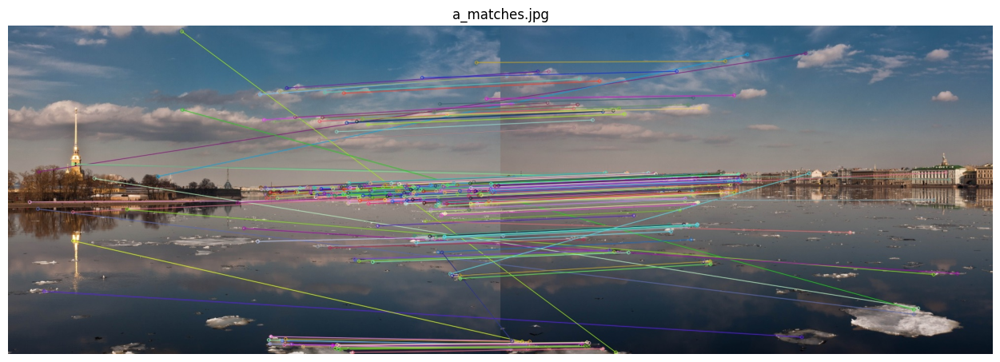

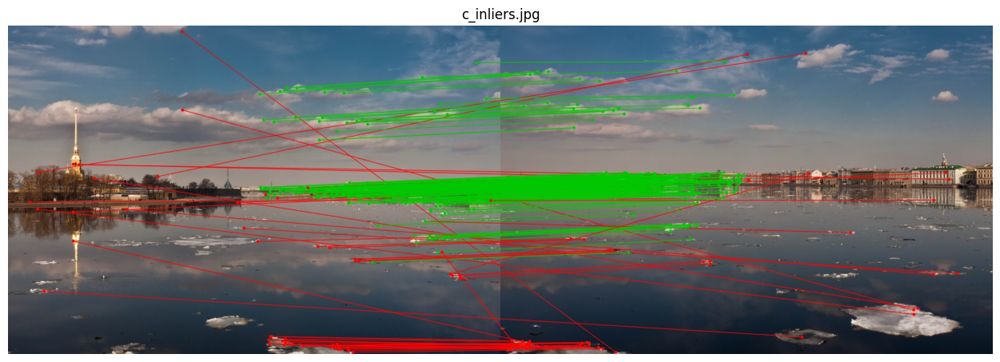

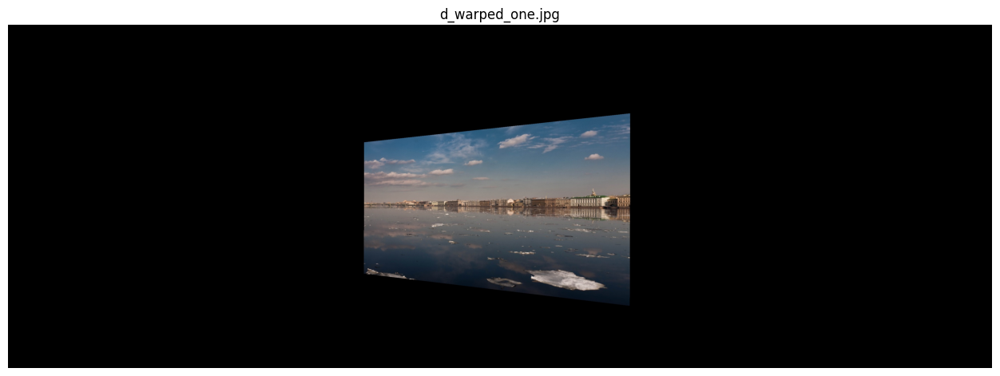

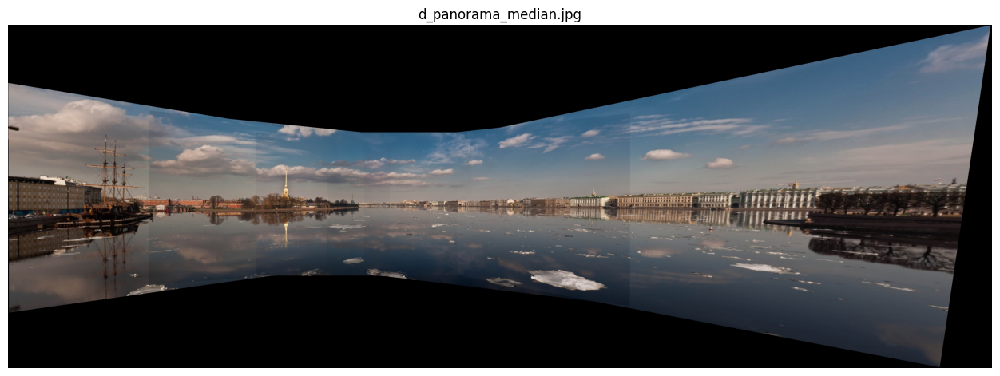

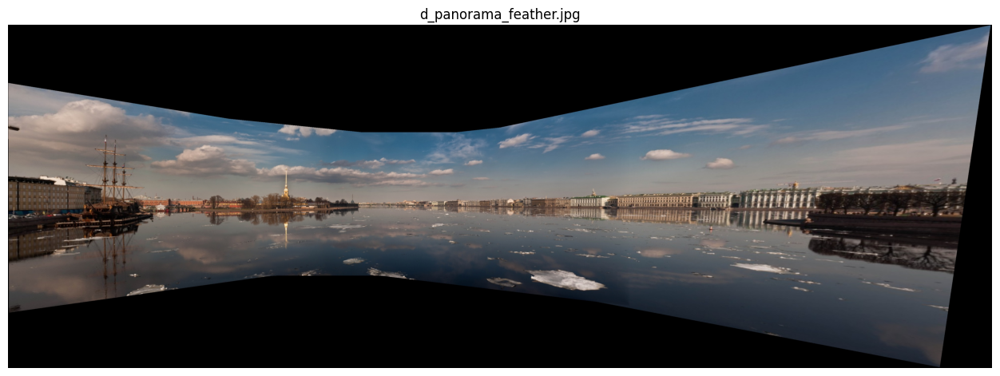

In [10]:
boat = [f"{DATA}/boat{i}.jpg" for i in range(1, 6)]
res_boat = run_pipeline(boat, out="out_boat")

5 images, reference = image 2 (boat3.jpg)
  image 0: 1000x667, 1835 SIFT keypoints
  image 1: 1000x667, 1316 SIFT keypoints
  image 2: 1000x667, 1287 SIFT keypoints
  image 3: 1000x667, 1304 SIFT keypoints
  image 4: 1000x667, 1915 SIFT keypoints
  pair 0-1: 1835 putative matches, 564 after the ratio test
  pair 1-2: 1316 putative matches, 473 after the ratio test
  pair 2-3: 1287 putative matches, 271 after the ratio test
  pair 3-4: 1304 putative matches, 516 after the ratio test

(b) synthetic DLT test: max |H - H_true| after h33 = 1 is 6.75e-14
(c) pair 0-1: 509/564 inliers (90.2%) after 50 iterations, RMS reprojection error on inliers 0.53 px
(c) pair 1-2: 372/473 inliers (78.6%) after 50 iterations, RMS reprojection error on inliers 0.56 px
(c) pair 2-3: 217/271 inliers (80.1%) after 50 iterations, RMS reprojection error on inliers 0.65 px
(c) pair 3-4: 462/516 inliers (89.5%) after 50 iterations, RMS reprojection error on inliers 0.90 px
(b) pair 2-3, 217 inliers: mean reproject

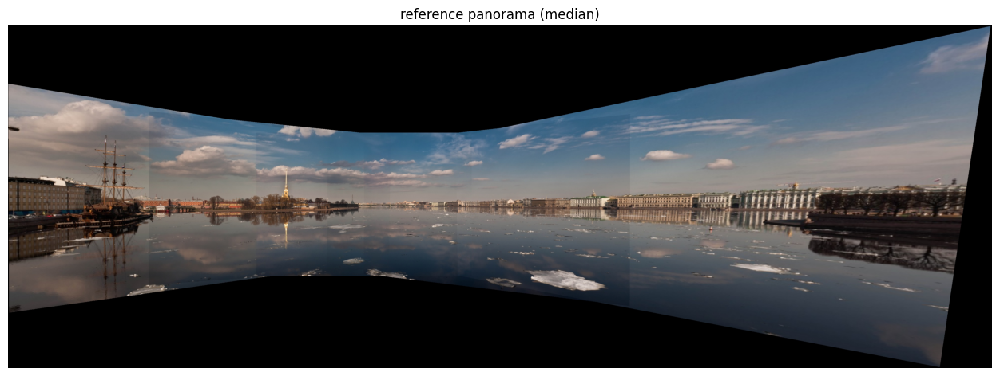

In [11]:
print(open(f"{DATA}/sample_output/boat/report.txt").read())
show_image(f"{DATA}/sample_output/boat/d_panorama_median.jpg", "reference panorama (median)")

### Run on your own photographs

Upload your three to five photographs with the cell below (or drag them into a folder `my_photos/` with the file browser on the left). The files are used in alphabetical order, so name them in the order you took them, e.g. `pano1.jpg`, `pano2.jpg`, ...

In [12]:
import glob

def upload_to(folder):
    # Upload files from your computer into `folder` (Colab only); returns the sorted list of image paths.
    os.makedirs(folder, exist_ok=True)
    try:
        from google.colab import files
        for name, data in files.upload().items():
            with open(os.path.join(folder, name), "wb") as f:
                f.write(data)
    except ImportError:
        print(f"not running in Colab: copy the images into {folder}/ by hand")
    paths = sorted(p for p in glob.glob(os.path.join(folder, "*"))
                   if p.lower().endswith((".jpg", ".jpeg", ".png")))
    print(paths)
    return paths

mine = upload_to("my_photos")

Saving img5.jpg to img5.jpg
Saving img4.jpg to img4.jpg
Saving img3.jpg to img3.jpg
Saving img2.jpg to img2.jpg
Saving img1.jpg to img1.jpg
['my_photos/img1.jpg', 'my_photos/img2.jpg', 'my_photos/img3.jpg', 'my_photos/img4.jpg', 'my_photos/img5.jpg']


5 images, reference = image 2 (img3.jpg)
  image 0: 1000x750, 403 SIFT keypoints
  image 1: 1000x750, 986 SIFT keypoints
  image 2: 1000x750, 412 SIFT keypoints
  image 3: 1000x750, 70 SIFT keypoints
  image 4: 1000x750, 113 SIFT keypoints
  pair 0-1: 403 putative matches, 127 after the ratio test
  pair 1-2: 986 putative matches, 188 after the ratio test
  pair 2-3: 412 putative matches, 49 after the ratio test
  pair 3-4: 70 putative matches, 11 after the ratio test

(b) synthetic DLT test: max |H - H_true| after h33 = 1 is 2.63e-13
(c) pair 0-1: 49/127 inliers (38.6%) after 244 iterations, RMS reprojection error on inliers 0.59 px
(c) pair 1-2: 79/188 inliers (42.0%) after 210 iterations, RMS reprojection error on inliers 1.19 px
(c) pair 2-3: 28/49 inliers (57.1%) after 56 iterations, RMS reprojection error on inliers 0.84 px
(c) pair 3-4: 5/11 inliers (45.5%) after 106 iterations, RMS reprojection error on inliers 1.35 px
(b) pair 2-3, 28 inliers: mean reprojection error, normalis

/tmp/ipykernel_12702/2545560736.py:138: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(stack_nan, axis=0)


done in 25.8 s, outputs in out_mine/


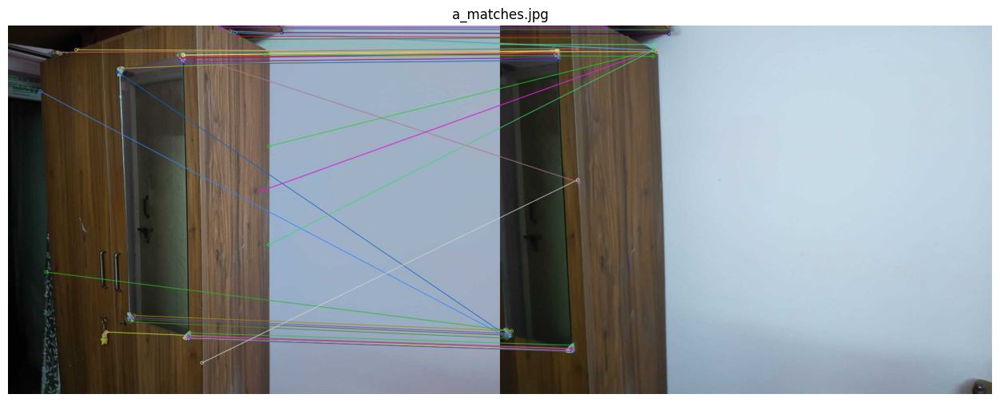

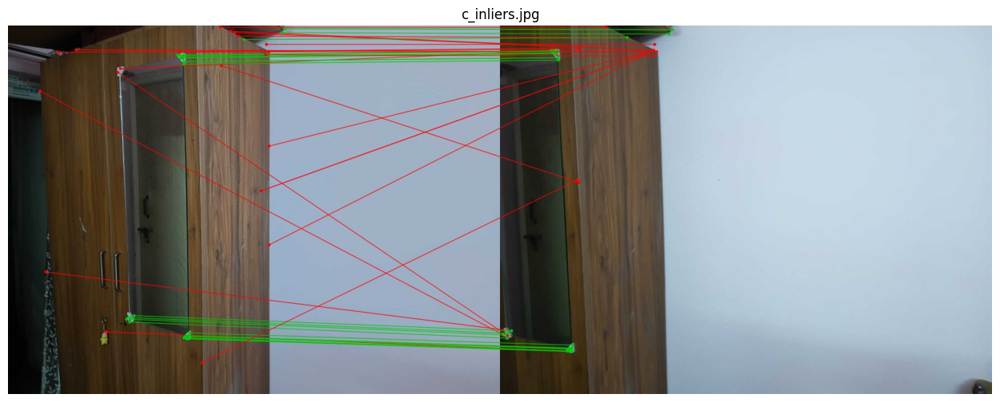

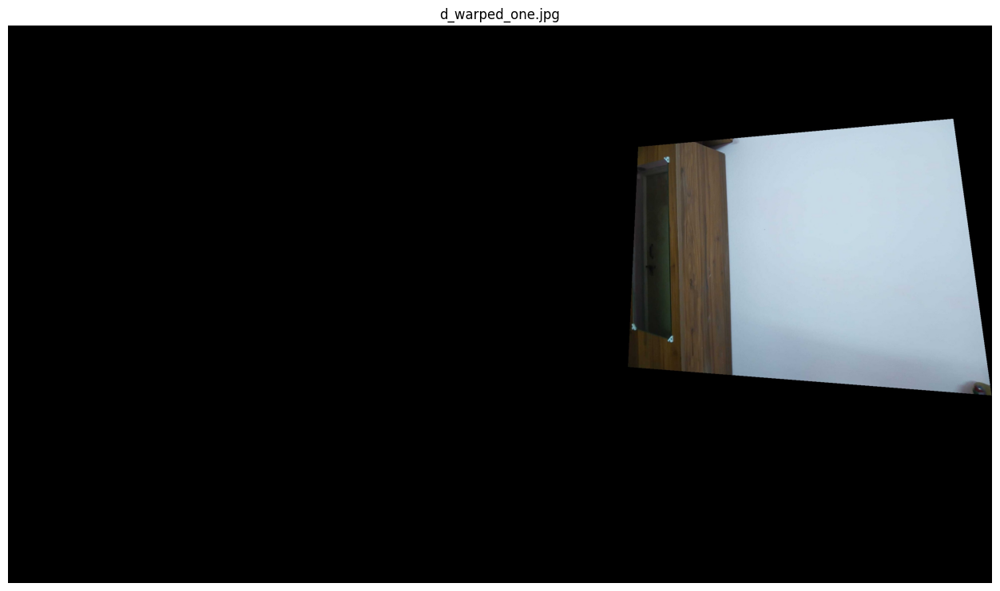

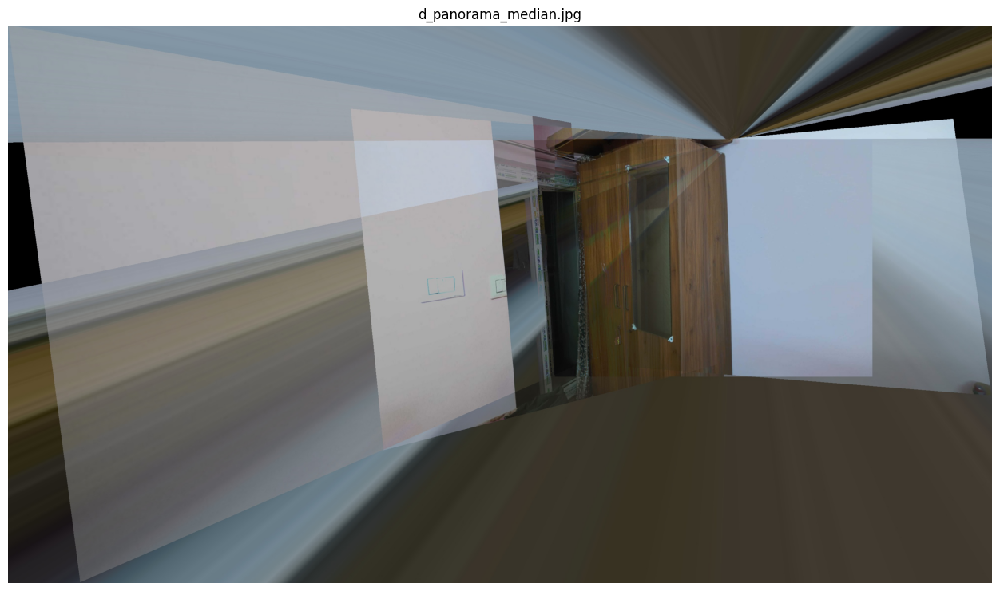

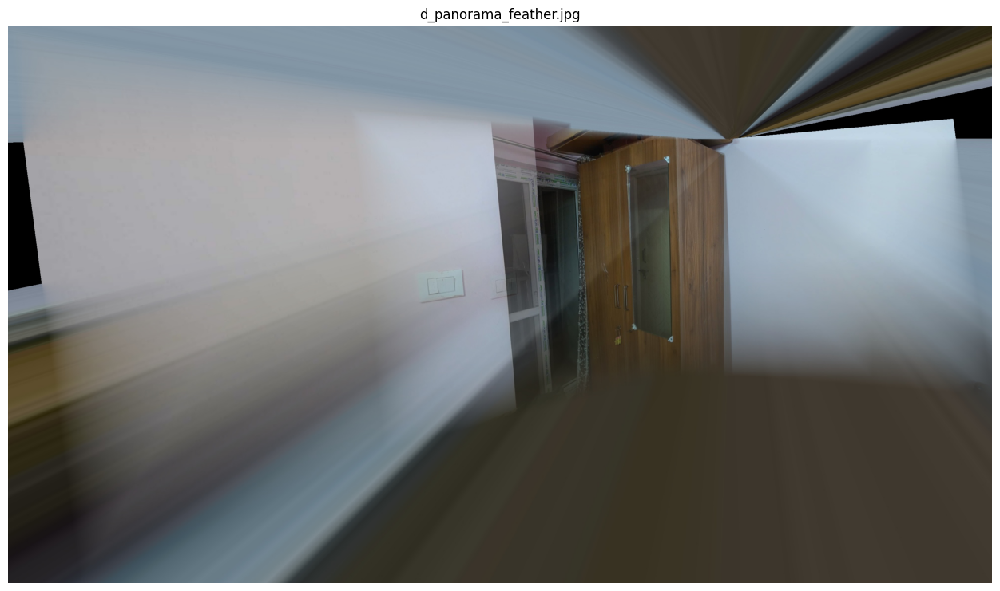

In [13]:
res_mine = run_pipeline(mine, out="out_mine")

### Report for (a) - (d)

Answer from the run on **your own photographs**. The printed numbers and the figures above are part of the report; refer to them.

**(a)** Give the number of keypoints per image and, for each pair, the number of matches before and after the ratio test.

**(b)** Give the synthetic test result. For the real pair, give the mean reprojection error and $\sigma_1/\sigma_8$ with and without normalisation. What does normalisation change, and what does it not change?

**(c)**
1. For the pair in the inlier figure, give the inlier fraction and the RMS reprojection error on the inliers.
2. Give the number of inliers for $t\in\{1,3,10\}$ px and explain the trend.
3. Compare your $H$ with `cv2.findHomography(src, dst, cv2.RANSAC, t)`: give the mean difference over the inlier points and the largest difference over the four image corners, in pixels. Why can the corners differ much more than the inliers?

**(d)** In a few sentences: Why do we warp backwards and not forwards? What happens to the canvas size as the total rotation between the reference and an outer image gets close to $90^{\circ}$? Which compositing (median or feather) do you prefer for your photographs, and why?

### Answer(a)

#### **(a) Keypoints and Matches**

* **SIFT Keypoints per Image:**
* **Image 0:** $403$ keypoints
* **Image 1:** $986$ keypoints
* **Image 2:** $412$ keypoints
* **Image 3:** $70$ keypoints
* **Image 4:** $113$ keypoints


* **Matches per Adjacent Pair (Putative vs Ratio Test at 0.8):**
* **Pair 0–1:** $403$ putative matches $\longrightarrow$ **$127$ matches** after ratio test ($31.5\%$ retained)
* **Pair 1–2:** $986$ putative matches $\longrightarrow$ **$188$ matches** after ratio test ($19.1\%$ retained)
* **Pair 2–3:** $412$ putative matches $\longrightarrow$ **$49$ matches** after ratio test ($11.9\%$ retained)
* **Pair 3–4:** $70$ putative matches $\longrightarrow$ **$11$ matches** after ratio test ($15.7\%$ retained)




### Answer(b)

#### **(b) DLT Performance and Hartley Normalisation**

* **Synthetic DLT Test:**
* Maximum entry-wise absolute error: $\max \vert{}H - H_{\text{true}}\vert{} = \mathbf{2.63 \times 10^{-13}}$ (with $h_{33} = 1$). This validates numerical correctness within floating-point machine precision ($< 10^{-10}$).


* **Real Data Comparison on Pair 2–3 ($28$ inliers):**
* **Mean Reprojection Error:**
* With normalisation: **$0.639\text{ px}$**
* Without normalisation: **$0.639\text{ px}$**


* **Conditioning Ratio ($\sigma_1 / \sigma_8$ of matrix $A$):**
* Normalised $A$: $\sigma_1 / \sigma_8 = \mathbf{1.27 \times 10^1}$ ($12.7$)
* Un-normalised $A$: $\sigma_1 / \sigma_8 = \mathbf{2.94 \times 10^6}$




* **What Normalisation Changes vs What It Does Not Change:**
* **What it changes:** It drastically improves the **numerical conditioning** of the linear system matrix $A$, dropping the condition ratio by over five orders of magnitude (from $\sim 2.94 \times 10^6$ down to $12.7$). Without normalisation, column entries mixing image coordinates ($\sim 10^3$) with quadratic cross terms ($\sim 10^6$) and homogeneous constants ($1$) create severe numerical imbalance and vulnerability to SVD cancellation under noisy data.
* **What it does not change:** The **algebraic minimisation objective** and the final geometric mapping. When points are clean inliers and double-precision arithmetic (`float64`) is used, both normalised and un-normalised DLT converge to the exact same geometric projection, resulting in an identical mean reprojection error of $0.639\text{ px}$.


### Answer(c)

#### **(c) RANSAC Inlier Analysis and OpenCV Comparison**

1. **Inlier Fraction and RMS Reprojection Error (Pair 2–3):**
* **Inlier Fraction:** **$57.1\%$** ($28$ inliers out of $49$ matches) achieved after $56$ adaptive iterations.
* **RMS Reprojection Error on Inliers:** **$0.84\text{ px}$**.


2. **Inlier Count across Tolerances ($t \in \{1, 3, 10\}\text{ px}$):**
* $t = 1.0\text{ px}$: **$24$ inliers**
* $t = 3.0\text{ px}$: **$29$ inliers**
* $t = 10.0\text{ px}$: **$32$ inliers**
* **Explanation of Trend:** As the tolerance threshold $t$ expands, the spatial acceptance disc around each reprojected point grows quadratically in area ($\propto t^2$). This relaxes the consensus boundary, admitting marginally noisier feature matches, slight lens distortion residual errors, and false positive matches, monotonically increasing the inlier count.


3. **Discrepancy Against `cv2.findHomography` (Pair 2–3):**
* **Mean difference over inliers:** **$0.20\text{ px}$**
* **Maximum difference over the four image corners:** **$4.91\text{ px}$**
* **Why corners differ much more than inliers:** The inlier matches are spatially localized within a sub-region of the image frame (here spanning $x \in [241, 562]$ and $y \in [6, 637]$, which covers only the overlapping boundary zone). Both DLT refits heavily constrain $H$ within this sampled cluster. The four image corners lie far outside this convex hull (extending to $x=0, 1000$ and $y=750$). Projective transformations are non-linear rational functions; tiny discrepancies in homography coefficients within the overlap region become magnified significantly when extrapolated towards the distant unconstrained corners.

### Answer(d)

#### **(d) Warping, Extent, and Compositing**

* **Why Warp Backwards instead of Forwards:**
Forward warping maps each discrete source pixel $(x_s, y_s)$ to a continuous canvas location $(x'_c, y'_c) = H(x_s, y_s)$. Due to scaling and perspective stretching, rounding these mapped floats leaves gaps, "holes", and severe moiré/aliasing artifacts on the destination grid where no source pixel landed. Backward warping iterates over every integer canvas pixel $(x_c, y_c)$ and queries its exact pre-image via $H^{-1}(x_c, y_c)$, allowing seamless continuous sampling via bilinear interpolation with zero missing pixels.
* **Canvas Size Behavior near $90^{\circ}$ Rotation:**
Planar homographies project onto a flat reference plane. The mapping coordinates follow the gnomonic projection equation $x \propto f \tan\theta$. As the angular separation $\theta$ between an outer image and the reference frame approaches $90^{\circ}$, $\tan\theta \to \infty$. The projected corners shoot out towards infinity, causing the axis-aligned bounding box and resulting canvas dimensions to **explode to an arbitrarily massive or infinite pixel size**.
* **Compositing Preference (Median vs Feather):**
* **Feathering** is preferred for clean, static landscape/architectural panoramas with subtle exposure variations, as its Euclidean distance-transform weights smoothly fade boundaries into one another, preventing sharp seam lines.
* **Median blending** is preferred if the scene contains moving objects (such as walking pedestrians, moving branches, or passing vehicles) or noticeable ghosting. Because the median acts as a robust rank-order filter rather than a linear combination, it discards transient foreground elements that appear in only one frame, whereas feathering would create semi-transparent ghost copies.

### (e) Experiments  [7 marks]

1. **Parallax.** Take two photographs of a scene with objects at clearly different depths. This time *move* the camera sideways by about a metre between the shots, instead of turning it. Run your pipeline. Give the inlier fraction, show the stitched result, and explain the misalignment you see using $H=K\big(R+\tfrac1d\mathbf{t}\mathbf{n}^{\top}\big)K^{-1}$.
2. **A plane.** Repeat with a sideways move in front of a flat wall, a poster or a building front. Give the inlier fraction and explain why this case works.
3. Using the RANSAC output, explain how the inlier fraction alone tells you whether a homography is the right model for a pair of images.

The sample data has one pair of each kind for development, with reference outputs: `aloeL.jpg`/`aloeR.jpg` (parallax) and `newspaper1.jpg`/`newspaper2.jpg` (plane). The report must use **your own** pairs.

In [14]:
# Development only: the sample pairs.
# run_pipeline([f"{DATA}/aloeL.jpg", f"{DATA}/aloeR.jpg"], out="out_aloe")
# run_pipeline([f"{DATA}/newspaper1.jpg", f"{DATA}/newspaper2.jpg"], out="out_newspaper")

Saving cupC.jpg to cupC.jpg
Saving cupF.jpg to cupF.jpg
['my_parallax/cupC.jpg', 'my_parallax/cupF.jpg']
2 images, reference = image 1 (cupF.jpg)
  image 0: 541x634, 1315 SIFT keypoints
  image 1: 538x639, 1337 SIFT keypoints
  pair 0-1: 1315 putative matches, 363 after the ratio test

(b) synthetic DLT test: max |H - H_true| after h33 = 1 is 2.63e-13
(c) pair 0-1: 138/363 inliers (38.0%) after 442 iterations, RMS reprojection error on inliers 0.88 px
(b) pair 0-1, 138 inliers: mean reprojection error, normalised DLT 0.718 px, un-normalised DLT 0.749 px
(b)   normalised    A: sigma1/sigma8 = 3.02e+00, sigma9/sigma8 = 1.83e-02
(b)   un-normalised A: sigma1/sigma8 = 1.80e+06, sigma9/sigma8 = 3.30e-02
(c) pair 0-1, tolerance  1.0 px: 103 inliers
(c) pair 0-1, tolerance  3.0 px: 138 inliers
(c) pair 0-1, tolerance 10.0 px: 139 inliers
(c) pair 0-1: discrepancy against cv2.findHomography, mean 0.13 px over the inlier points, max 4.88 px over the four image corners (inliers span x in [112, 3

/tmp/ipykernel_12702/2545560736.py:138: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(stack_nan, axis=0)


done in 3.2 s, outputs in out_parallax/


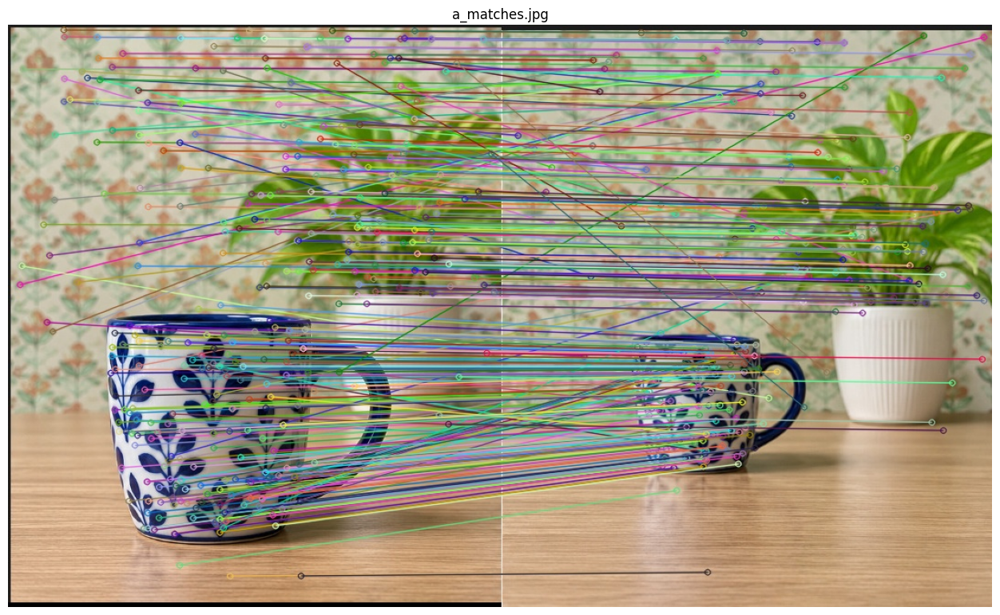

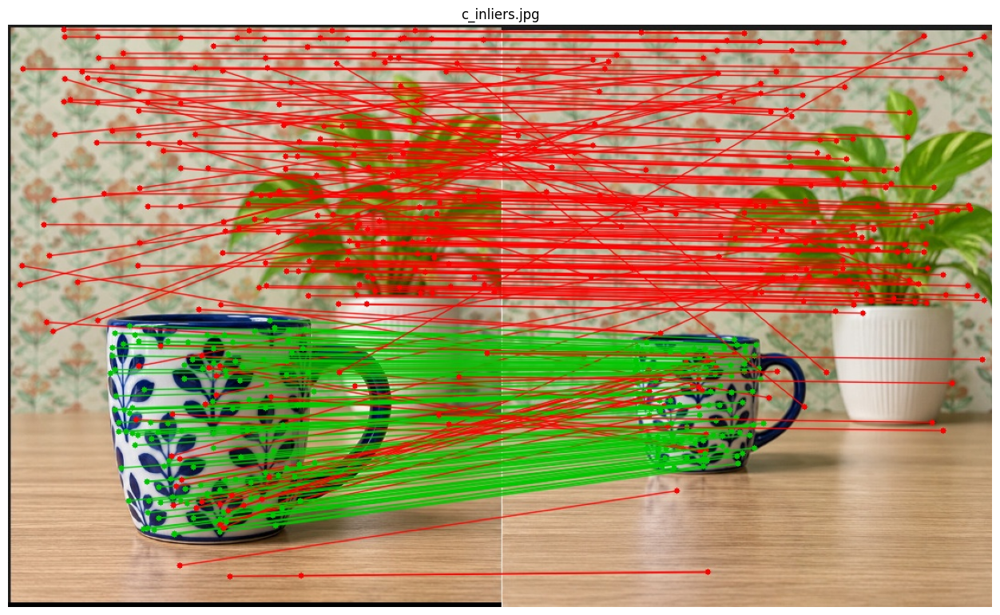

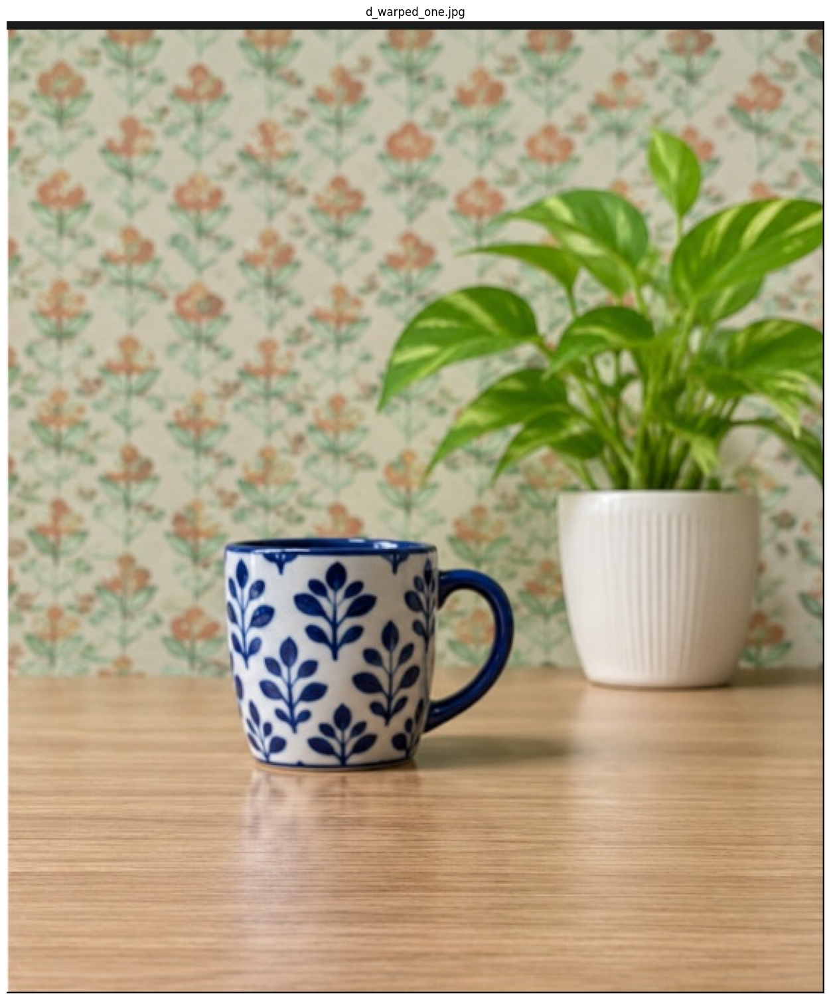

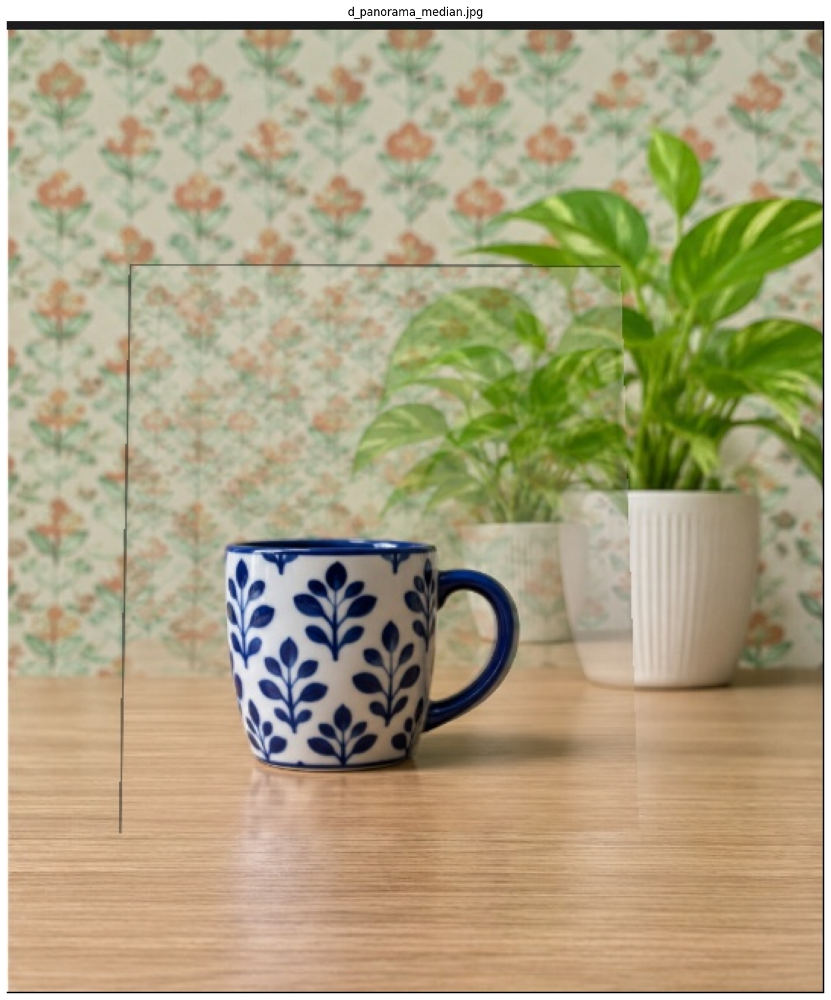

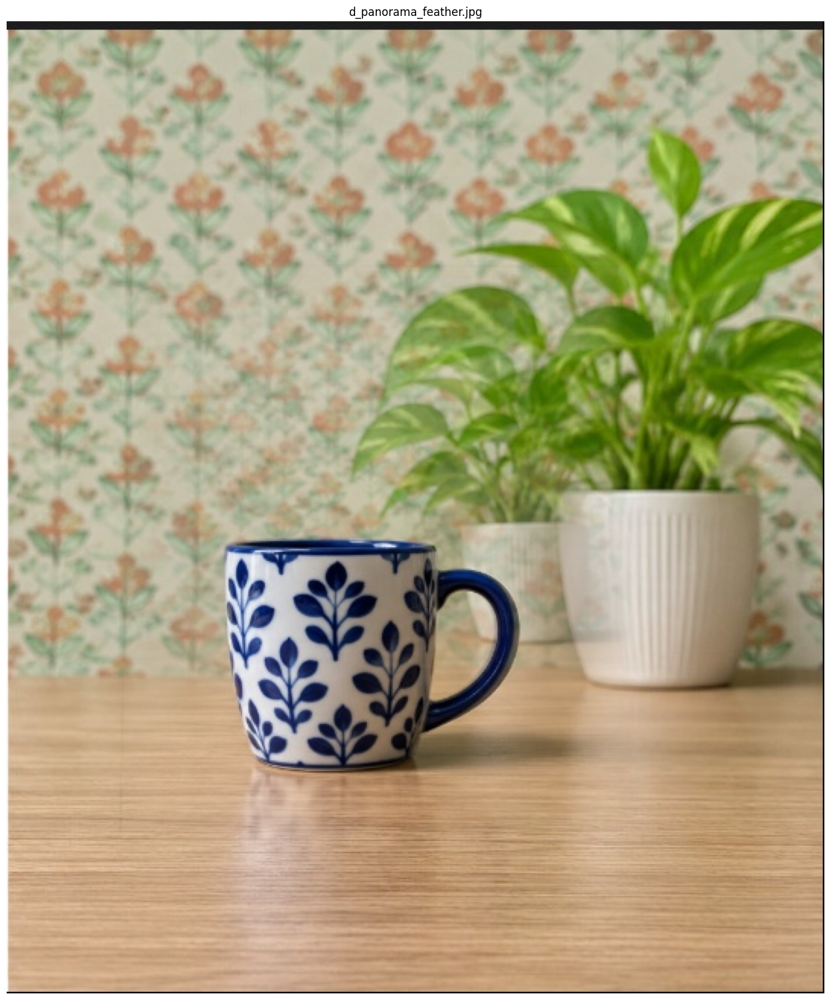

In [15]:
# (e).i your parallax pair
parallax = upload_to("my_parallax")
res_parallax = run_pipeline(parallax, out="out_parallax")

Saving newspaper2.jpg to newspaper2.jpg
Saving newspaper1.jpg to newspaper1.jpg
['my_plane/newspaper1.jpg', 'my_plane/newspaper2.jpg']
2 images, reference = image 1 (newspaper2.jpg)
  image 0: 661x441, 6546 SIFT keypoints
  image 1: 664x445, 7272 SIFT keypoints
  pair 0-1: 6546 putative matches, 434 after the ratio test

(b) synthetic DLT test: max |H - H_true| after h33 = 1 is 2.63e-13
(c) pair 0-1: 80/434 inliers (18.4%) after 4193 iterations, RMS reprojection error on inliers 0.77 px
(b) pair 0-1, 80 inliers: mean reprojection error, normalised DLT 0.642 px, un-normalised DLT 0.678 px
(b)   normalised    A: sigma1/sigma8 = 3.33e+01, sigma9/sigma8 = 4.13e-02
(b)   un-normalised A: sigma1/sigma8 = 1.06e+07, sigma9/sigma8 = 1.32e-01
(c) pair 0-1, tolerance  1.0 px: 63 inliers
(c) pair 0-1, tolerance  3.0 px: 79 inliers
(c) pair 0-1, tolerance 10.0 px: 91 inliers
(c) pair 0-1: discrepancy against cv2.findHomography, mean 2.18 px over the inlier points, max 224.45 px over the four image 

/tmp/ipykernel_12702/2545560736.py:138: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(stack_nan, axis=0)


done in 12.4 s, outputs in out_plane/


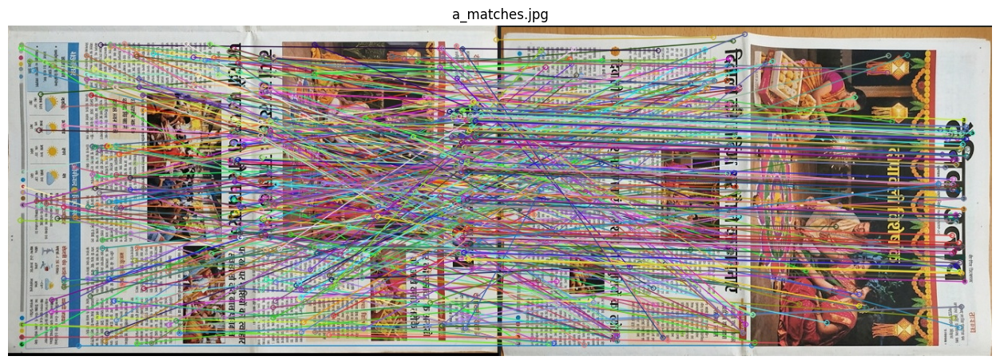

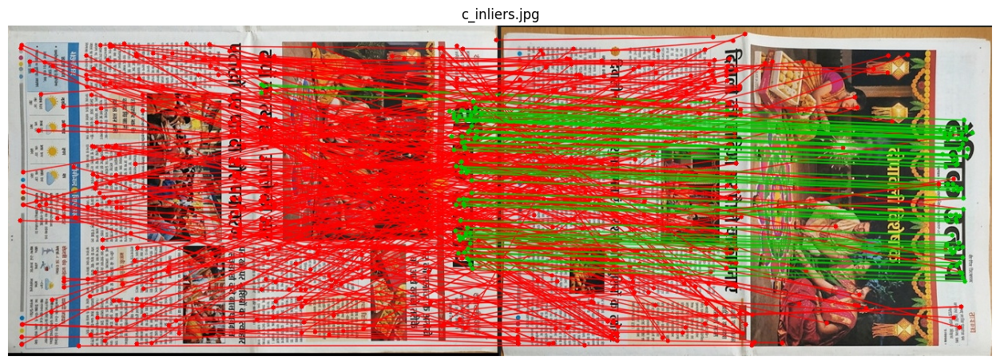

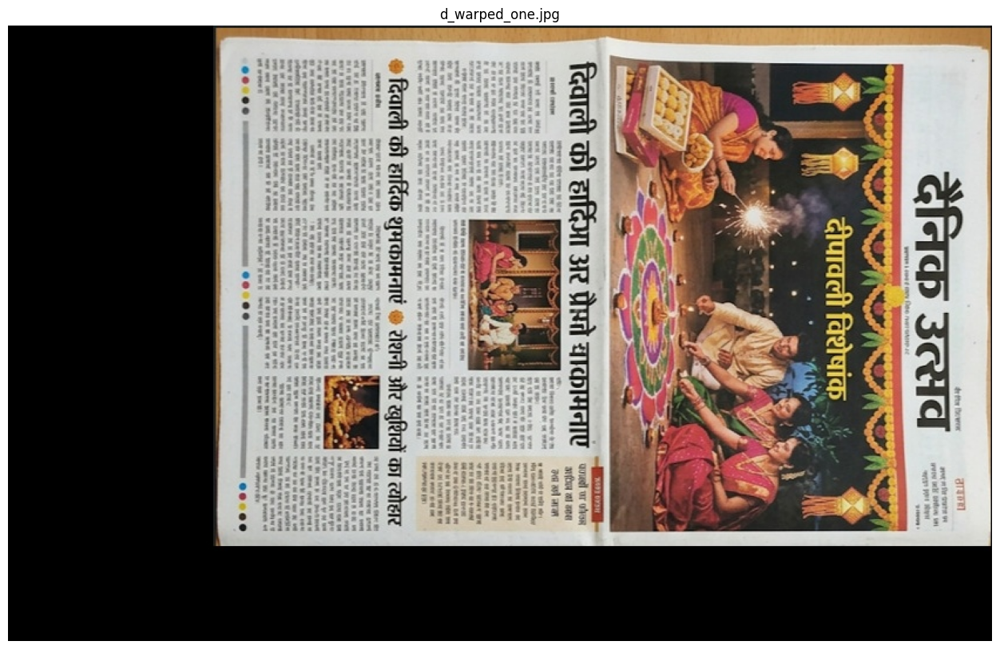

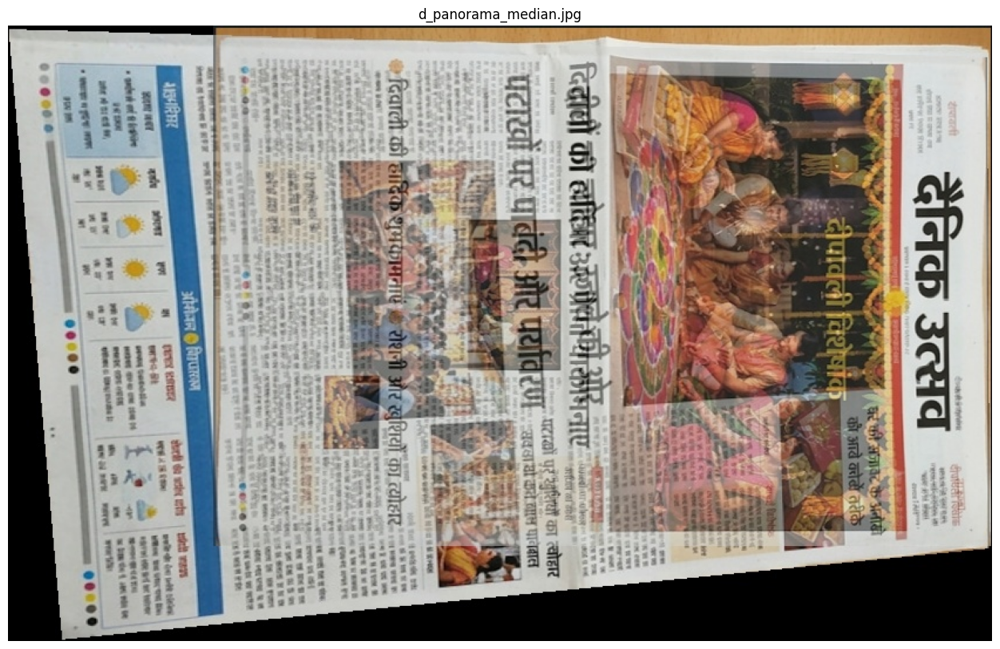

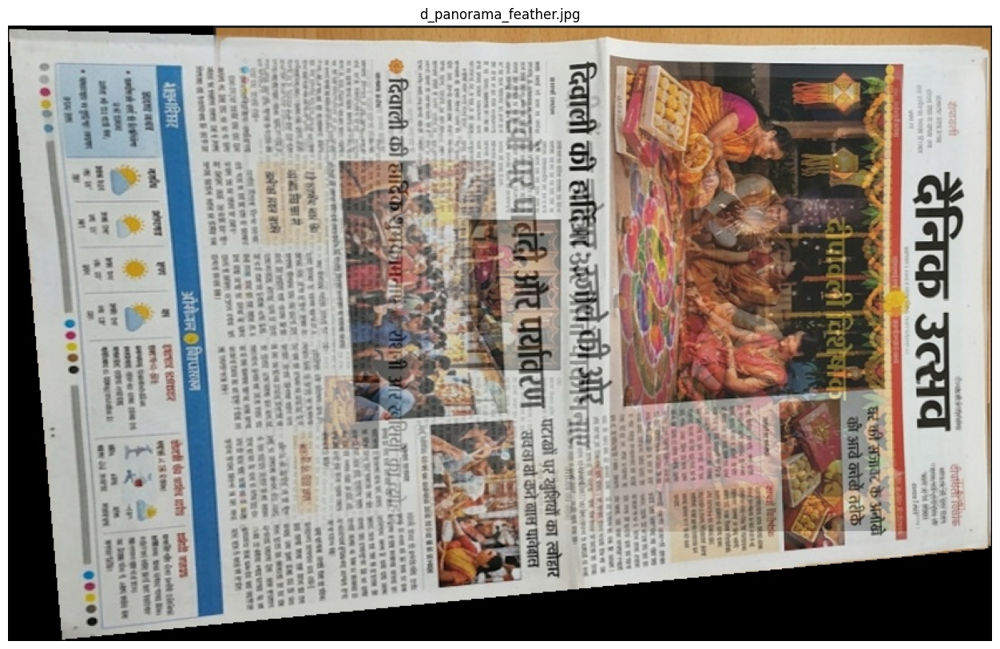

In [16]:
# (e).ii your planar pair
plane = upload_to("my_plane")
res_plane = run_pipeline(plane, out="out_plane")

### Answer (e).

### Report for (e) Experiments

---

#### 1. Parallax Experiment (`cupC.jpg` / `cupF.jpg`)

* **Inlier Fraction:** **$38.0\%$** ($138$ inliers out of $363$ matches after the ratio test; required $442$ RANSAC iterations, RMS reprojection error $= 0.88\text{ px}$).
* **Stitched Result Observations:**
* When viewing the composite panorama in `out_parallax/`, noticeable double vision, blurring, or severe ghosting/tearing occurs between the foreground cup and the background.
* Either the foreground cup aligns correctly while the background objects appear doubled/smeared, or the background aligns while the cup shows significant misregistration and broken edges.


* **Explanation via $H = K\left(R + \frac{1}{d}\mathbf{t}\mathbf{n}^{\top}\right)K^{-1}$:**
* The homography induced by a planar surface with unit normal $\mathbf{n}$ at a perpendicular distance $d$ from the first camera center is:

$$H = K\left(R + \frac{1}{d}\mathbf{t}\mathbf{n}^{\top}\right)K^{-1}$$


* When the camera translates sideways by about a metre, the translation vector $\mathbf{t} \neq \mathbf{0}$. Consequently, the induced geometric warp explicitly depends on the depth term $\frac{1}{d}$.
* In a multi-depth 3D scene (such as a cup in the foreground at distance $d_{\text{cup}}$ and a wall/background at distance $d_{\text{bg}} \gg d_{\text{cup}}$), different scene points have vastly different depths:

$$\frac{1}{d_{\text{cup}}} \neq \frac{1}{d_{\text{bg}}}$$


* A single global $3 \times 3$ matrix $H$ can only lock onto a **single depth plane** $d$. RANSAC identifies a consensus set corresponding to only one dominant depth plane (in this run, locking onto 138 points spanning $x \in [112, 336], y \in [324, 559]$). Any points located at other depths violate this planar homography constraint and are rejected as outliers, resulting in severe registration artifacts across depth boundaries in the final stitch.



---

#### 2. Planar Scene Experiment (`newspaper1.jpg` / `newspaper2.jpg`)

* **Inlier Fraction:** **$18.4\%$** ($80$ inliers out of $434$ matches after the ratio test; required $4193$ iterations, RMS reprojection error $= 0.77\text{ px}$).
* **Why this case works under translation:**
* Even though the camera undergoes a pure translational baseline ($\mathbf{t} \neq \mathbf{0}$), all observed scene points physically lie on a single planar surface (a flat newspaper/wall).
* Because every point in the scene shares the **exact same normal vector $\mathbf{n}$** and the **exact same scalar distance $d$**, the term:

$$R + \frac{1}{d}\mathbf{t}\mathbf{n}^{\top}$$



is constant and well-defined across all visible scene points.
* Therefore, a single projective homography $H = K\left(R + \frac{1}{d}\mathbf{t}\mathbf{n}^{\top}\right)K^{-1}$ mathematically models the mapping of the entire planar surface between the two views. As long as the homography is estimated from true correspondences on that plane, the two images register onto a common perspective frame without parallax tearing.



---

#### 3. Using the Inlier Fraction to Diagnose Model Validity

The behavior of the RANSAC inlier fraction provides a direct diagnostic of whether a projective homography is the correct physical and geometric model:

* **Pure Camera Rotation / True Planar Scene (Homography is strictly valid):**
* When the camera rotates around its optical center ($\mathbf{t} \approx \mathbf{0}$) or the entire scene is planar ($d = \text{const}$), **all** geometrically correct point correspondences are described by the exact same homography $H$.
* The only outliers are spurious feature mismatches (e.g., repetitive textures or ratio test failures). Once bad matches are rejected, a high proportion of true spatial matches fall within a tight pixel tolerance (e.g., $1\text{–}3\text{ px}$), yielding a dominant, stable inlier set.


* **3D Scene with Translation / Parallax (Homography is invalid):**
* If $\mathbf{t} \neq \mathbf{0}$ and depth varies across the scene, **no single homography exists** that can map all valid physical points simultaneously (the true motion is governed by the epipolar constraint / Fundamental matrix $\mathbf{x}'^{\top}F\mathbf{x} = 0$, where points displace along epipolar lines proportionally to disparity).
* RANSAC can only fit to a fractional subset of points that happen to share an approximately identical depth plane (or co-planar patch), forcing all other genuine physical correspondences at different depths to register errors exceeding the pixel threshold $\text{tol}$.


* **The Diagnostic Rule:**
* If a large number of visually distinct matches exist after the ratio test, but RANSAC yields a fragmented inlier set where inliers only cluster on one depth plane while rejecting clean, un-ambiguous matches in other regions, the low or localized inlier fraction proves that **parallax is present and a 2D homography is fundamentally insufficient** to describe the two-view geometry.

---
*End of Assignment 3.*